# Problem 1: 2D Heat Diffusion with Convergence Detection on a Tesla T4
### Part A: JOR and Red-Black SOR. Part B: Geometric Multigrid, the production solver

**Student ID:** G25AIT2026 &nbsp;|&nbsp; **Platform:** Google Colab, NVIDIA Tesla T4 (sm_75), CUDA C++

**Runtime setup:** *Runtime > Change runtime type > T4 GPU*, then *Runtime > Run all*. The full run takes about 10 to 15 minutes.

### Problem
Steady heat conduction on an $N\times N$ grid. Every interior cell is updated with the five-point stencil

$$T_{i,j}^{t+1}=\tfrac14\left(T_{i-1,j}^{t}+T_{i+1,j}^{t}+T_{i,j-1}^{t}+T_{i,j+1}^{t}\right)$$

until $\max_{i,j}|T^{t+1}_{i,j}-T^{t}_{i,j}|<\varepsilon$, with fixed-temperature (Dirichlet) boundaries.
Input: $N$, initial grid, boundary conditions, $\varepsilon$. Output: converged grid, iteration count, execution time.

### What this notebook implements
| | Global memory | Shared-memory tiling |
|---|---|---|
| **JOR** (Jacobi Over-Relaxation, $\omega=1$ is the stencil above) | `jor_global` | `jor_shared` |
| **RB-SOR** (Red-Black Gauss-Seidel with SOR, $\omega=1$ gives RB-GS) | `rb_global` | `rb_shared` |

* **Parallel convergence test on the device:** each kernel reduces $|T^{new}-T^{old}|$ with warp shuffles, issues one `atomicMax` per block into a per-iteration history array, and the next iteration's kernels exit early once the value is below $\varepsilon$.
* **Minimal transfers:** the grid crosses PCIe once in and once out; the host reads a 4-byte flag every $K=200$ iterations.
* **Precision:** `double` by default, `float` optional (Section 7 shows why SOR needs `double`).

### Contents
**Part A (classic iterations):** 1. Environment check  2. CUDA source  3. Build  4. Quick run and correctness  5. Convergence study  6. Relaxation factor  7. Convergence histories and precision  8. Throughput: global vs shared  9. Cost of host polling  10. Figures and tables  11. Custom boundary conditions from a file

**Part B (geometric multigrid):** 12. Why Jacobi and Gauss-Seidel get slow  13. The multigrid idea  14. GPU implementation  15. First run  16. Cycles versus grid size  17. Accuracy  18. Histories, smoothing, levels  19. GPU performance and CUDA Graphs  20. Figures  21. What to remember and a production checklist

22. (Optional) Rebuild the IEEE report and the slides with the measured numbers

## 1. Environment check

In [1]:
!nvidia-smi
!nvcc --version | tail -2

Fri Oct 16 17:34:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. CUDA source (`heat2d.cu`)
Single translation unit, templated on precision. Command-line interface:

```
./heat2d [-n N] [-e eps] [-m jor|rbsor|all] [-v global|shared|both] [-p double|float]
         [-w omega] [--maxit M] [--batch K] [-i init.bin] [-o out.bin] [--hist hist.csv]
         [--top T --bottom T --left T --right T --init T] [--verify] [-q]
```
`init.bin` / `out.bin` are raw $N\times N$ float64 arrays (row-major). The outer ring of `init.bin` is the fixed boundary.
Each run prints one machine-readable `RESULT,...` line per solver/variant.

In [2]:
%%writefile heat2d.cu
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <cmath>
#include <string>
#include <vector>
#include <chrono>
#include <algorithm>
#include <cuda_runtime.h>

#define CUDA_CHECK(call)                                                        \
    do {                                                                        \
        cudaError_t err_ = (call);                                              \
        if (err_ != cudaSuccess) {                                              \
            fprintf(stderr, "CUDA error %s at %s:%d\n",                         \
                    cudaGetErrorString(err_), __FILE__, __LINE__);              \
            exit(EXIT_FAILURE);                                                 \
        }                                                                       \
    } while (0)

constexpr int BX = 32;
constexpr int BY = 8;

template <typename real> __device__ __forceinline__ real dAbs(real x) { return x < real(0) ? -x : x; }
template <typename real> __device__ __forceinline__ real dMax(real a, real b) { return a > b ? a : b; }

template <typename real>
__device__ __forceinline__ real warpMax(real v) {
#pragma unroll
    for (int off = 16; off > 0; off >>= 1)
        v = dMax(v, __shfl_down_sync(0xffffffffu, v, off));
    return v;
}

__device__ __forceinline__ void atomicMaxNonNeg(float* dst, float v) {
    atomicMax(reinterpret_cast<int*>(dst), __float_as_int(v));
}
__device__ __forceinline__ void atomicMaxNonNeg(double* dst, double v) {
    atomicMax(reinterpret_cast<unsigned long long*>(dst),
              (unsigned long long)__double_as_longlong(v));
}

template <typename real>
__device__ __forceinline__ void blockMaxToGlobal(real v, real* dst) {
    __shared__ real warpVals[32];
    const int tid    = threadIdx.y * blockDim.x + threadIdx.x;
    const int lane   = tid & 31;
    const int wid    = tid >> 5;
    const int nWarps = (blockDim.x * blockDim.y + 31) >> 5;

    v = warpMax(v);
    if (lane == 0) warpVals[wid] = v;
    __syncthreads();
    if (wid == 0) {
        v = (lane < nWarps) ? warpVals[lane] : real(0);
        v = warpMax(v);
        if (lane == 0 && v > real(0)) atomicMaxNonNeg(dst, v);
    }
}

template <typename real>
__device__ __forceinline__ bool alreadyConverged(const real* hist, int it,
                                                 real eps, int* convIt) {
    if (it > 1 && hist[it - 1] < eps) {
        if (blockIdx.x == 0 && blockIdx.y == 0 &&
            threadIdx.x == 0 && threadIdx.y == 0 && *convIt == 0)
            *convIt = it - 1;
        return true;
    }
    return false;
}

template <typename real>
__global__ void jor_global(const real* __restrict__ Tin, real* __restrict__ Tout,
                           int N, real w, real* hist, int it, real eps,
                           int* convIt) {
    if (alreadyConverged(hist, it, eps, convIt)) return;

    const int j = blockIdx.x * blockDim.x + threadIdx.x;
    const int i = blockIdx.y * blockDim.y + threadIdx.y;
    real d = 0;
    if (i > 0 && i < N - 1 && j > 0 && j < N - 1) {
        const size_t id = (size_t)i * N + j;
        const real old = Tin[id];
        const real avg = real(0.25) * (Tin[id - N] + Tin[id + N] + Tin[id - 1] + Tin[id + 1]);
        const real nv  = old + w * (avg - old);
        Tout[id] = nv;
        d = dAbs(nv - old);
    }
    blockMaxToGlobal(d, &hist[it]);
}

template <typename real>
__global__ void jor_shared(const real* __restrict__ Tin, real* __restrict__ Tout,
                           int N, real w, real* hist, int it, real eps,
                           int* convIt) {
    if (alreadyConverged(hist, it, eps, convIt)) return;

    __shared__ real s[BY + 2][BX + 2];
    const int tx = threadIdx.x, ty = threadIdx.y;
    const int gi0 = blockIdx.y * BY - 1;
    const int gj0 = blockIdx.x * BX - 1;

    for (int y = ty; y < BY + 2; y += BY)
        for (int x = tx; x < BX + 2; x += BX) {
            const int gi = gi0 + y, gj = gj0 + x;
            s[y][x] = (gi >= 0 && gi < N && gj >= 0 && gj < N)
                          ? Tin[(size_t)gi * N + gj] : real(0);
        }
    __syncthreads();

    const int i = gi0 + ty + 1, j = gj0 + tx + 1;
    real d = 0;
    if (i > 0 && i < N - 1 && j > 0 && j < N - 1) {
        const real old = s[ty + 1][tx + 1];
        const real avg = real(0.25) * (s[ty][tx + 1] + s[ty + 2][tx + 1] +
                                   s[ty + 1][tx] + s[ty + 1][tx + 2]);
        const real nv  = old + w * (avg - old);
        Tout[(size_t)i * N + j] = nv;
        d = dAbs(nv - old);
    }
    blockMaxToGlobal(d, &hist[it]);
}

template <typename real>
__global__ void rb_global(real* __restrict__ T, int N, real w, int color,
                          real* hist, int it, real eps, int* convIt) {
    if (alreadyConverged(hist, it, eps, convIt)) return;

    const int tx = blockIdx.x * blockDim.x + threadIdx.x;
    const int i  = blockIdx.y * blockDim.y + threadIdx.y;
    const int j  = 2 * tx + ((i + color) & 1);
    real d = 0;
    if (i > 0 && i < N - 1 && j > 0 && j < N - 1) {
        const size_t id = (size_t)i * N + j;
        const real old = T[id];
        const real avg = real(0.25) * (T[id - N] + T[id + N] + T[id - 1] + T[id + 1]);
        const real nv  = old + w * (avg - old);
        T[id] = nv;
        d = dAbs(nv - old);
    }
    blockMaxToGlobal(d, &hist[it]);
}

template <typename real>
__global__ void rb_shared(real* __restrict__ T, int N, real w, int color,
                          real* hist, int it, real eps, int* convIt) {
    if (alreadyConverged(hist, it, eps, convIt)) return;

    constexpr int TW = 2 * BX;
    __shared__ real s[BY + 2][TW + 2];
    const int tx = threadIdx.x, ty = threadIdx.y;
    const int gi0 = blockIdx.y * BY - 1;
    const int gj0 = blockIdx.x * TW - 1;
    const int tid = ty * BX + tx;

    for (int k = tid; k < (BY + 2) * (TW + 2); k += BX * BY) {
        const int y = k / (TW + 2), x = k % (TW + 2);
        const int gi = gi0 + y, gj = gj0 + x;
        s[y][x] = (gi >= 0 && gi < N && gj >= 0 && gj < N)
                      ? T[(size_t)gi * N + gj] : real(0);
    }
    __syncthreads();

    const int i  = gi0 + 1 + ty;
    const int lj = 2 * tx + ((i + color) & 1);
    const int j  = gj0 + 1 + lj;
    real d = 0;
    if (i > 0 && i < N - 1 && j > 0 && j < N - 1) {
        const real old = s[ty + 1][lj + 1];
        const real avg = real(0.25) * (s[ty][lj + 1] + s[ty + 2][lj + 1] +
                                   s[ty + 1][lj] + s[ty + 1][lj + 2]);
        const real nv  = old + w * (avg - old);
        T[(size_t)i * N + j] = nv;
        d = dAbs(nv - old);
    }
    blockMaxToGlobal(d, &hist[it]);
}

struct Config {
    int    N        = 512;
    double eps      = 1e-4;
    double omega    = -1.0;
    int    maxIter  = 1000000;
    int    batch    = 200;
    double top = 100.0, bottom = 0.0, left = 75.0, right = 50.0, init = 0.0;
    std::string method    = "all";
    std::string variant   = "both";
    std::string precision = "double";
    std::string inFile, outFile, histFile;
    bool   verify   = false;
    bool   quiet    = false;
};

struct Result {
    std::string method, variant;
    int    iters = 0;
    bool   converged = false;
    double omega = 1.0, lastDiff = 0.0;
    double kernelMs = 0.0, totalMs = 0.0;
    std::vector<double> grid, hist;
};

static double optimalOmega(int N) {
    const double PI = 3.14159265358979323846;
    return 2.0 / (1.0 + std::sin(PI / (double)(N - 1)));
}

static void buildInitialGrid(const Config& c, std::vector<double>& g) {
    const int N = c.N;
    g.assign((size_t)N * N, c.init);
    if (!c.inFile.empty()) {
        FILE* f = fopen(c.inFile.c_str(), "rb");
        if (!f) { fprintf(stderr, "cannot open %s\n", c.inFile.c_str()); exit(1); }
        size_t got = fread(g.data(), sizeof(double), g.size(), f);
        fclose(f);
        if (got != g.size()) { fprintf(stderr, "init file must hold N*N float64\n"); exit(1); }
        return;
    }
    for (int j = 0; j < N; ++j) { g[j] = c.top; g[(size_t)(N - 1) * N + j] = c.bottom; }
    for (int i = 1; i < N - 1; ++i) { g[(size_t)i * N] = c.left; g[(size_t)i * N + N - 1] = c.right; }
}

template <typename real>
static Result runGPU(const Config& c, const std::string& method,
                     const std::string& variant, const std::vector<double>& h0d) {
    const int N = c.N;
    const size_t bytes = (size_t)N * N * sizeof(real);
    Result r; r.method = method; r.variant = variant;
    r.omega = (c.omega > 0.0) ? c.omega : (method == "jor" ? 1.0 : optimalOmega(N));
    const real w = (real)r.omega, eps = (real)c.eps;
    std::vector<real> h0(h0d.begin(), h0d.end());

    auto t0 = std::chrono::high_resolution_clock::now();

    real *dA = nullptr, *dB = nullptr, *dHist = nullptr; int* dConv = nullptr;
    CUDA_CHECK(cudaMalloc(&dA, bytes));
    if (method == "jor") CUDA_CHECK(cudaMalloc(&dB, bytes));
    CUDA_CHECK(cudaMalloc(&dHist, (size_t)(c.maxIter + 2) * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&dConv, sizeof(int)));
    CUDA_CHECK(cudaMemset(dHist, 0, (size_t)(c.maxIter + 2) * sizeof(real)));
    CUDA_CHECK(cudaMemset(dConv, 0, sizeof(int)));

    CUDA_CHECK(cudaMemcpy(dA, h0.data(), bytes, cudaMemcpyHostToDevice));
    if (dB) CUDA_CHECK(cudaMemcpy(dB, dA, bytes, cudaMemcpyDeviceToDevice));

    const dim3 block(BX, BY);
    const dim3 gridJ((N + BX - 1) / BX, (N + BY - 1) / BY);
    const int  halfW = (N + 1) / 2;
    const dim3 gridR((halfW + BX - 1) / BX, (N + BY - 1) / BY);

    cudaEvent_t e0, e1;
    CUDA_CHECK(cudaEventCreate(&e0)); CUDA_CHECK(cudaEventCreate(&e1));
    CUDA_CHECK(cudaEventRecord(e0));

    int convIt = 0, it = 1;
    const bool shared = (variant == "shared");
    while (it <= c.maxIter && convIt == 0) {
        const int end = std::min(it + c.batch, c.maxIter + 1);
        for (; it < end; ++it) {
            if (method == "jor") {
                const real* src = (it & 1) ? dA : dB;
                real*       dst = (it & 1) ? dB : dA;
                if (shared) jor_shared<real><<<gridJ, block>>>(src, dst, N, w, dHist, it, eps, dConv);
                else        jor_global<real><<<gridJ, block>>>(src, dst, N, w, dHist, it, eps, dConv);
            } else {
                if (shared) {
                    rb_shared<real><<<gridR, block>>>(dA, N, w, 0, dHist, it, eps, dConv);
                    rb_shared<real><<<gridR, block>>>(dA, N, w, 1, dHist, it, eps, dConv);
                } else {
                    rb_global<real><<<gridR, block>>>(dA, N, w, 0, dHist, it, eps, dConv);
                    rb_global<real><<<gridR, block>>>(dA, N, w, 1, dHist, it, eps, dConv);
                }
            }
        }
        CUDA_CHECK(cudaGetLastError());

        CUDA_CHECK(cudaMemcpy(&convIt, dConv, sizeof(int), cudaMemcpyDeviceToHost));
    }
    CUDA_CHECK(cudaEventRecord(e1));
    CUDA_CHECK(cudaEventSynchronize(e1));
    float ms = 0.f; CUDA_CHECK(cudaEventElapsedTime(&ms, e0, e1));
    r.kernelMs = ms;

    if (convIt == 0) {
        real last = 1;
        CUDA_CHECK(cudaMemcpy(&last, dHist + c.maxIter, sizeof(real), cudaMemcpyDeviceToHost));
        if (last < eps) convIt = c.maxIter;
    }
    r.converged = (convIt > 0);
    r.iters = r.converged ? convIt : c.maxIter;

    const real* dRes = dA;
    if (method == "jor") dRes = (r.iters & 1) ? dB : dA;

    std::vector<real> g((size_t)N * N), h(r.iters);
    CUDA_CHECK(cudaMemcpy(g.data(), dRes, bytes, cudaMemcpyDeviceToHost));
    if (r.iters) CUDA_CHECK(cudaMemcpy(h.data(), dHist + 1, r.iters * sizeof(real), cudaMemcpyDeviceToHost));
    r.grid.assign(g.begin(), g.end());
    r.hist.assign(h.begin(), h.end());
    r.lastDiff = r.iters ? r.hist.back() : 0.0;

    auto t1 = std::chrono::high_resolution_clock::now();
    r.totalMs = std::chrono::duration<double, std::milli>(t1 - t0).count();

    cudaEventDestroy(e0); cudaEventDestroy(e1);
    cudaFree(dA); if (dB) cudaFree(dB); cudaFree(dHist); cudaFree(dConv);
    return r;
}

template <typename real>
static Result runCPU(const Config& c, const std::string& method,
                     const std::vector<double>& h0d, double omegaD) {
    const int N = c.N;
    const real omega = (real)omegaD, eps = (real)c.eps;
    Result r; r.method = method; r.variant = "cpu"; r.omega = omegaD;
    std::vector<real> A(h0d.begin(), h0d.end()), B = A;
    auto t0 = std::chrono::high_resolution_clock::now();
    int it = 0;
    for (it = 1; it <= c.maxIter; ++it) {
        real dmax = 0;
        if (method == "jor") {
            const std::vector<real>& src = (it & 1) ? A : B;
            std::vector<real>&       dst = (it & 1) ? B : A;
            for (int i = 1; i < N - 1; ++i)
                for (int j = 1; j < N - 1; ++j) {
                    const size_t id = (size_t)i * N + j;
                    const real old = src[id];
                    const real avg = real(0.25) * (src[id - N] + src[id + N] + src[id - 1] + src[id + 1]);
                    const real nv  = old + omega * (avg - old);
                    dst[id] = nv; dmax = std::max(dmax, (real)std::fabs(nv - old));
                }
        } else {
            for (int color = 0; color < 2; ++color)
                for (int i = 1; i < N - 1; ++i)
                    for (int j = 1 + ((i + color + 1) & 1); j < N - 1; j += 2) {
                        const size_t id = (size_t)i * N + j;
                        const real old = A[id];
                        const real avg = real(0.25) * (A[id - N] + A[id + N] + A[id - 1] + A[id + 1]);
                        const real nv  = old + omega * (avg - old);
                        A[id] = nv; dmax = std::max(dmax, (real)std::fabs(nv - old));
                    }
        }
        r.hist.push_back(dmax);
        if (dmax < eps) { r.converged = true; break; }
    }
    r.iters = std::min(it, c.maxIter);
    const std::vector<real>& res = (method == "jor" && (r.iters & 1)) ? B : A;
    r.grid.assign(res.begin(), res.end());
    r.totalMs = r.kernelMs = std::chrono::duration<double, std::milli>(
        std::chrono::high_resolution_clock::now() - t0).count();
    return r;
}

static void usage(const char* p) {
    printf("usage: %s [-n N] [-e eps] [-m jor|rbsor|all] [-v global|shared|both]\n"
           "          [-p double|float] [-w omega] [--maxit M] [--batch K]\n"
           "          [-i init.bin] [-o out.bin] [--hist hist.csv]\n"
           "          [--top T --bottom T --left T --right T --init T] [--verify] [-q]\n"
           "  init.bin / out.bin : raw N*N float64, row-major; edges of init.bin are the BCs\n", p);
}

static Result dispatchGPU(const Config& c, const std::string& m, const std::string& v,
                          const std::vector<double>& h0) {
    return (c.precision == "float") ? runGPU<float>(c, m, v, h0) : runGPU<double>(c, m, v, h0);
}
static Result dispatchCPU(const Config& c, const std::string& m, const std::vector<double>& h0, double w) {
    return (c.precision == "float") ? runCPU<float>(c, m, h0, w) : runCPU<double>(c, m, h0, w);
}

int main(int argc, char** argv) {
    Config c;
    for (int a = 1; a < argc; ++a) {
        std::string s = argv[a];
        auto nxt = [&](void) -> const char* {
            if (a + 1 >= argc) { usage(argv[0]); exit(1); } return argv[++a]; };
        if      (s == "-n")        c.N = atoi(nxt());
        else if (s == "-e")        c.eps = atof(nxt());
        else if (s == "-m")        c.method = nxt();
        else if (s == "-v")        c.variant = nxt();
        else if (s == "-p")        c.precision = nxt();
        else if (s == "-w")        c.omega = atof(nxt());
        else if (s == "--maxit")   c.maxIter = std::max(1, atoi(nxt()));
        else if (s == "--batch")   c.batch = std::max(1, atoi(nxt()));
        else if (s == "-i")        c.inFile = nxt();
        else if (s == "-o")        c.outFile = nxt();
        else if (s == "--hist")    c.histFile = nxt();
        else if (s == "--top")     c.top = atof(nxt());
        else if (s == "--bottom")  c.bottom = atof(nxt());
        else if (s == "--left")    c.left = atof(nxt());
        else if (s == "--right")   c.right = atof(nxt());
        else if (s == "--init")    c.init = atof(nxt());
        else if (s == "--verify")  c.verify = true;
        else if (s == "-q")        c.quiet = true;
        else if (s == "-h" || s == "--help") { usage(argv[0]); return 0; }
        else { usage(argv[0]); return 1; }
    }
    if (c.N < 3) { fprintf(stderr, "N must be >= 3\n"); return 1; }
    if (c.precision != "float" && c.precision != "double") { usage(argv[0]); return 1; }

    cudaDeviceProp prop; CUDA_CHECK(cudaGetDeviceProperties(&prop, 0));
    if (!c.quiet)
        printf("# device: %s  SMs=%d  N=%d  eps=%g  precision=%s  maxit=%d  batch=%d\n",
               prop.name, prop.multiProcessorCount, c.N, c.eps, c.precision.c_str(),
               c.maxIter, c.batch);

    std::vector<double> h0; buildInitialGrid(c, h0);

    { Config w = c; w.maxIter = 2; dispatchGPU(w, "jor", "global", h0); dispatchGPU(w, "rbsor", "shared", h0); }

    std::vector<std::string> methods, variants;
    if (c.method == "all") methods = {"jor", "rbsor"}; else methods = {c.method};
    if (c.variant == "both") variants = {"global", "shared"}; else variants = {c.variant};

    const double bytesPerVal = (c.precision == "float") ? 4.0 : 8.0;
    printf("RESULT,method,variant,precision,N,omega,eps,iters,converged,final_diff,kernel_ms,total_ms,MLUPS,GBps\n");
    for (auto& m : methods)
        for (auto& v : variants) {
            Result r = dispatchGPU(c, m, v, h0);
            const double cells = (double)(c.N - 2) * (c.N - 2) * r.iters;
            const double mlups = cells / (r.kernelMs * 1e3);
            const double gbps  = cells * 2.0 * bytesPerVal / (r.kernelMs * 1e6);
            printf("RESULT,%s,%s,%s,%d,%.6f,%g,%d,%d,%.3e,%.3f,%.3f,%.1f,%.1f\n",
                   m.c_str(), v.c_str(), c.precision.c_str(), c.N, r.omega, c.eps, r.iters,
                   (int)r.converged, r.lastDiff, r.kernelMs, r.totalMs, mlups, gbps);

            const bool many = methods.size() * variants.size() > 1;
            if (!c.outFile.empty()) {
                std::string fn = many ? (m + "_" + v + "_" + c.outFile) : c.outFile;
                FILE* f = fopen(fn.c_str(), "wb");
                fwrite(r.grid.data(), sizeof(double), r.grid.size(), f); fclose(f);
            }
            if (!c.histFile.empty()) {
                std::string fn = m + "_" + v + "_" + c.histFile;
                FILE* f = fopen(fn.c_str(), "w");
                fprintf(f, "iter,maxdiff\n");
                for (size_t k = 0; k < r.hist.size(); ++k) fprintf(f, "%zu,%.6e\n", k + 1, r.hist[k]);
                fclose(f);
            }
            if (c.verify) {
                Result cr = dispatchCPU(c, m, h0, r.omega);
                double maxErr = 0.0;
                for (size_t k = 0; k < cr.grid.size(); ++k)
                    maxErr = std::max(maxErr, std::fabs(cr.grid[k] - r.grid[k]));

                const double tol = (c.precision == "float") ? std::max(5e-2, 10.0 * c.eps) : 10.0 * c.eps;
                printf("VERIFY,%s,%s,cpu_iters=%d,gpu_iters=%d,max_abs_diff=%.3e,cpu_ms=%.1f,speedup=%.1f,%s\n",
                       m.c_str(), v.c_str(), cr.iters, r.iters, maxErr, cr.totalMs,
                       cr.totalMs / r.kernelMs, (maxErr < tol ? "PASS" : "FAIL"));
            }
            if (!c.quiet) {
                const int N = c.N; const auto& g = r.grid;
                printf("#   T(N/4,N/2)=%.4f  T(N/2,N/2)=%.4f  T(3N/4,N/2)=%.4f\n",
                       g[(size_t)(N / 4) * N + N / 2], g[(size_t)(N / 2) * N + N / 2],
                       g[(size_t)(3 * N / 4) * N + N / 2]);
            }
        }
    return 0;
}

Writing heat2d.cu


## 3. Build
The architecture is read from the GPU (sm_75 on a T4) so the notebook also works on other Colab GPUs. `-Xptxas -v` reports registers and shared memory per kernel.

In [3]:
import subprocess
cc = subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"],
                    capture_output=True, text=True).stdout.strip().split("\n")[0].replace(".", "")
ARCH = f"sm_{cc}" if cc else "sm_75"
print("compiling for", ARCH)
!nvcc -O3 -arch={ARCH} -lineinfo -Xptxas -v -o heat2d heat2d.cu 2>&1 | grep -E "Compiling entry|Used|error|warning" | sed 's/ptxas info    : //'
!ls -la heat2d

compiling for sm_75
Compiling entry function '_Z9rb_globalIdEvPT_iS0_iS1_iS0_Pi' for 'sm_75'
Used 20 registers, used 1 barriers, 256 bytes smem, 416 bytes cmem[0]
Compiling entry function '_Z9rb_sharedIdEvPT_iS0_iS1_iS0_Pi' for 'sm_75'
Used 38 registers, used 1 barriers, 5536 bytes smem, 416 bytes cmem[0]
Compiling entry function '_Z10jor_globalIdEvPKT_PS0_iS0_S3_iS0_Pi' for 'sm_75'
Used 20 registers, used 1 barriers, 256 bytes smem, 416 bytes cmem[0]
Compiling entry function '_Z10jor_sharedIdEvPKT_PS0_iS0_S3_iS0_Pi' for 'sm_75'
Used 38 registers, used 1 barriers, 2976 bytes smem, 416 bytes cmem[0]
Compiling entry function '_Z9rb_globalIfEvPT_iS0_iS1_iS0_Pi' for 'sm_75'
Used 18 registers, used 1 barriers, 128 bytes smem, 400 bytes cmem[0]
Compiling entry function '_Z9rb_sharedIfEvPT_iS0_iS1_iS0_Pi' for 'sm_75'
Used 36 registers, used 1 barriers, 2768 bytes smem, 400 bytes cmem[0]
Compiling entry function '_Z10jor_globalIfEvPKT_PS0_iS0_S3_iS0_Pi' for 'sm_75'
Used 18 registers, used 1 ba

## 4. Quick run and correctness
All four kernels at $N=512$, then `--verify`, which reruns the identical algorithm sequentially on the CPU and compares the stopping iteration and the grid.

In [4]:
!./heat2d -n 512 -e 1e-4 -m all -v both

# device: Tesla T4  SMs=40  N=512  eps=0.0001  precision=double  maxit=1000000  batch=200
RESULT,method,variant,precision,N,omega,eps,iters,converged,final_diff,kernel_ms,total_ms,MLUPS,GBps
RESULT,jor,global,double,512,1.000000,0.0001,150654,1,1.000e-04,6150.573,6155.243,6371.0,101.9
#   T(N/4,N/2)=72.9764  T(N/2,N/2)=50.8585  T(3N/4,N/2)=28.4172
RESULT,jor,shared,double,512,1.000000,0.0001,150654,1,1.000e-04,6803.098,6808.094,5759.9,92.2
#   T(N/4,N/2)=72.9764  T(N/2,N/2)=50.8585  T(3N/4,N/2)=28.4172
RESULT,rbsor,global,double,512,1.987779,0.0001,1040,1,9.652e-05,46.403,50.241,5829.4,93.3
#   T(N/4,N/2)=76.7463  T(N/2,N/2)=56.1446  T(3N/4,N/2)=32.1115
RESULT,rbsor,shared,double,512,1.987779,0.0001,1040,1,9.652e-05,50.694,54.296,5336.0,85.4
#   T(N/4,N/2)=76.7463  T(N/2,N/2)=56.1446  T(3N/4,N/2)=32.1115


In [5]:
import pandas as pd, numpy as np, os, json, math, time, shutil
pd.set_option("display.width", 160)
DATA = "data"; os.makedirs(DATA, exist_ok=True)
COLS = ["method","variant","precision","N","omega","eps","iters","converged","final_diff",
        "kernel_ms","total_ms","MLUPS","GBps"]

def run(*args, quiet=True):
    cmd = ["./heat2d"] + [str(a) for a in args] + (["-q"] if quiet else [])
    p = subprocess.run(cmd, capture_output=True, text=True)
    if p.returncode != 0:
        raise RuntimeError(p.stderr + p.stdout)
    rows = [l.split(",")[1:] for l in p.stdout.splitlines()
            if l.startswith("RESULT,") and not l.startswith("RESULT,method")]
    df = pd.DataFrame(rows, columns=COLS)
    for c in COLS[3:]:
        df[c] = pd.to_numeric(df[c])
    return df, [l for l in p.stdout.splitlines() if l.startswith("VERIFY")]

def solver_name(m, w):
    return "JOR" if m == "jor" else ("RB-GS" if abs(w - 1) < 1e-9 else "RB-SOR")

def omega_opt(N):
    return 2.0 / (1.0 + math.sin(math.pi / (N - 1)))

open(f"{DATA}/device.txt", "w").write(
    subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                   capture_output=True, text=True).stdout.strip().split("\n")[0])
print("device:", open(f"{DATA}/device.txt").read())

device: Tesla T4


In [6]:
checks = [("-n", 128, "-m", "all"), ("-n", 255, "-m", "all"),
          ("-n", 200, "-m", "jor", "-p", "float"), ("-n", 200, "-m", "rbsor", "-w", 1.0, "-p", "float")]
for c in checks:
    _, ver = run(*c, "--verify")
    for v in ver:
        print(" ".join(map(str, c)).ljust(32), v)

-n 128 -m all                    VERIFY,jor,global,cpu_iters=18404,gpu_iters=18404,max_abs_diff=0.000e+00,cpu_ms=896.6,speedup=9.9,PASS
-n 128 -m all                    VERIFY,jor,shared,cpu_iters=18404,gpu_iters=18404,max_abs_diff=0.000e+00,cpu_ms=899.5,speedup=8.5,PASS
-n 128 -m all                    VERIFY,rbsor,global,cpu_iters=276,gpu_iters=276,max_abs_diff=3.979e-13,cpu_ms=13.8,speedup=5.1,PASS
-n 128 -m all                    VERIFY,rbsor,shared,cpu_iters=276,gpu_iters=276,max_abs_diff=3.979e-13,cpu_ms=13.9,speedup=4.9,PASS
-n 255 -m all                    VERIFY,jor,global,cpu_iters=55496,gpu_iters=55496,max_abs_diff=0.000e+00,cpu_ms=11241.0,speedup=16.9,PASS
-n 255 -m all                    VERIFY,jor,shared,cpu_iters=55496,gpu_iters=55496,max_abs_diff=0.000e+00,cpu_ms=11293.1,speedup=12.7,PASS
-n 255 -m all                    VERIFY,rbsor,global,cpu_iters=530,gpu_iters=530,max_abs_diff=6.111e-13,cpu_ms=101.5,speedup=4.7,PASS
-n 255 -m all                    VERIFY,rbsor,shar

## 5. Convergence study ($\varepsilon=10^{-4}$, float64)
Three solvers: JOR ($\omega=1$), RB-GS ($\omega=1$), RB-SOR ($\omega^*=2/(1+\sin\pi h)$), each with the global and the shared kernel.
The error of each converged grid is measured against an RB-SOR solution converged to $10^{-10}$.
JOR at $N=1024$ needs several hundred thousand iterations, so this cell takes a few minutes.

In [7]:
SIZES_ALL = [64, 128, 256, 512, 1024]
SIZES_SOR = [2048, 4096]
SOLVERS = [("jor", 1.0), ("rbsor", 1.0), ("rbsor", -1)]
conv, iters_rows = [], []
t0 = time.time()
for N in SIZES_ALL + SIZES_SOR:
    ref = None
    if N in SIZES_ALL:
        run("-n", N, "-m", "rbsor", "-v", "global", "-e", 1e-10, "-o", f"{DATA}/ref.bin")
        ref = np.fromfile(f"{DATA}/ref.bin")
    for m, w in SOLVERS:
        if N in SIZES_SOR and not (m == "rbsor" and w < 0):
            continue
        for v in ["global", "shared"]:
            out = f"{DATA}/out.bin"
            df, _ = run("-n", N, "-m", m, "-v", v, "-w", w, "-o", out)
            df["solver"] = solver_name(m, df.omega[0])
            conv.append(df)
            if v == "global":
                err = float(np.abs(np.fromfile(out) - ref).max()) if ref is not None else float("nan")
                iters_rows.append(dict(solver=df.solver[0], N=N, iters=int(df.iters[0]),
                                       max_err=err, precision="double"))
        print(f"N={N:5d} done  ({time.time() - t0:6.1f} s)")
conv = pd.concat(conv, ignore_index=True)
conv.to_csv(f"{DATA}/gpu_conv.csv", index=False)
pd.DataFrame(iters_rows).to_csv(f"{DATA}/iters.csv", index=False)
os.remove(f"{DATA}/ref.bin"); os.remove(f"{DATA}/out.bin")
conv.pivot_table(index=["solver", "N"], columns="variant", values=["iters", "kernel_ms"]).round(2)

N=   64 done  (   1.0 s)
N=   64 done  (   1.5 s)
N=   64 done  (   2.0 s)
N=  128 done  (   3.0 s)
N=  128 done  (   3.6 s)
N=  128 done  (   4.1 s)
N=  256 done  (   6.2 s)
N=  256 done  (   7.7 s)
N=  256 done  (   8.2 s)
N=  512 done  (  22.4 s)
N=  512 done  (  32.1 s)
N=  512 done  (  32.8 s)
N= 1024 done  ( 155.1 s)
N= 1024 done  ( 257.6 s)
N= 1024 done  ( 259.2 s)
N= 2048 done  ( 267.2 s)
N= 4096 done  ( 324.9 s)


iters           kernel_ms          
variant        global    shared    global    shared
solver N                                           
JOR    64      5655.0    5655.0     28.32     31.39
       128    18404.0   18404.0     90.69    105.57
       256    55830.0   55830.0    666.58    730.56
       512   150654.0  150654.0   6303.83   7032.94
       1024  311637.0  311637.0  56922.46  63586.26
RB-GS  64      3107.0    3107.0     26.04     29.66
       128    10336.0   10336.0     77.12     87.52
       256    32483.0   32483.0    492.99    550.58
       512    93660.0   93660.0   4345.58   4839.01
       1024  228375.0  228375.0  47076.41  54798.65
RB-SOR 64       144.0     144.0      1.38      1.41
       128      276.0     276.0      2.69      2.80
       256      531.0     531.0      8.38      9.11
       512     1040.0    1040.0     44.96     50.27
       1024    2035.0    2035.0    412.08    478.23
       2048    4014.0    4014.0   3201.82   3714.96
       4096    7869.0    7869.0  25382.94  29434.51

## 6. Relaxation factor sweep (RB-SOR, $N=256$)

In [8]:
N = 256
ws = [1.0, 1.2, 1.4, 1.6, 1.7, 1.8, 1.9, 1.95, 1.97, round(omega_opt(N), 6), 1.98, 1.99]
om = []
for w in ws:
    df, _ = run("-n", N, "-m", "rbsor", "-v", "global", "-w", w)
    om.append(dict(N=N, omega=w, iters=int(df.iters[0])))
om = pd.DataFrame(om); om.to_csv(f"{DATA}/omega.csv", index=False)
jo = [(w, *run("-n", 128, "-m", "jor", "-v", "global", "-w", w, "--maxit", 200000)[0][["iters", "converged", "final_diff"]].values[0])
      for w in [0.5, 0.7, 0.9, 1.0, 1.01]]
display(om.T)
display(pd.DataFrame(jo, columns=["omega", "iters", "converged", "final_diff"]))

,0,1,2,3,4,5,6,7,8,9,10,11
N,256.0,256.0,256.0,256.0,256.0,256.0,256.0,256.00,256.00,256.000000,256.00,256.00
omega,1.0,1.2,1.4,1.6,1.7,1.8,1.9,1.95,1.97,1.975661,1.98,1.99
iters,32483.0,23436.0,16312.0,10401.0,7744.0,5207.0,2704.0,1385.00,770.00,531.000000,651.00,1262.00


,omega,iters,converged,final_diff
0,0.50,32278.0,1.0,0.0001
1,0.70,24626.0,1.0,0.0001
2,0.90,20066.0,1.0,0.0001
3,1.00,18404.0,1.0,0.0001
4,1.01,37974.0,1.0,0.0000


## 7. Convergence histories and the float32 limit of SOR
`--hist` writes $\max|T^{k}-T^{k-1}|$ for every iteration (copied from the device once, at the end).
The float32 SOR run is capped at 20 000 iterations: round-off is re-injected every sweep and damped only by $\omega^*-1$,
so it settles on a plateau of roughly $\text{ulp}(T)/(2-\omega^*)$, above $\varepsilon$.

In [9]:
N = 256
for m, w, key, extra in [("jor", 1.0, "jor_256", []), ("rbsor", 1.0, "gs_256", []), ("rbsor", -1, "sor_256", []),
                         ("rbsor", -1, "sorf", ["-p", "float", "--maxit", 20000])]:
    df, _ = run("-n", N, "-m", m, "-v", "global", "-w", w, "--hist", "h.csv", *extra)
    shutil.move(f"{m}_global_h.csv", f"{DATA}/hist_{key}.csv")
    print(f"{key:8s} iters={int(df.iters[0]):7d} converged={int(df.converged[0])} final max-change={df.final_diff[0]:.2e}")
shutil.copy(f"{DATA}/hist_sor_256.csv", f"{DATA}/hist_sord.csv")
json.dump({"sorf_N": N}, open(f"{DATA}/meta.json", "w"))
run("-n", 512, "-m", "rbsor", "-v", "shared", "-o", f"{DATA}/field_512.bin")
for f in os.listdir(DATA):
    if f.startswith("field_") and f != "field_512.bin":
        os.remove(f"{DATA}/{f}")

jor_256  iters=  55830 converged=1 final max-change=1.00e-04
gs_256   iters=  32483 converged=1 final max-change=1.00e-04
sor_256  iters=    531 converged=1 final max-change=9.74e-05
sorf     iters=  20000 converged=0 final max-change=4.96e-04


## 8. Throughput: global vs shared memory
Fixed 2000 iterations (`-e 0` disables the stop) so every kernel does the same work; median of 3 runs.
Effective bandwidth counts one read and one write per cell update.

In [10]:
bench = []
for N in [256, 512, 1024, 2048, 4096]:
    for p in ["float", "double"]:
        reps = [run("-n", N, "-m", "all", "-v", "both", "-p", p, "-e", 0, "--maxit", 2000)[0] for _ in range(3)]
        r = pd.concat(reps).groupby(["method", "variant", "precision", "N"], as_index=False).median(numeric_only=True)
        bench.append(r)
bench = pd.concat(bench, ignore_index=True)
bench.to_csv(f"{DATA}/gpu_bench.csv", index=False)
t = bench.pivot_table(index=["precision", "N"], columns=["method", "variant"], values="MLUPS").round(0)
display(t)
sp = bench.pivot_table(index=["precision", "N", "method"], columns="variant", values="kernel_ms")
sp["global/shared"] = (sp["global"] / sp["shared"]).round(3)
display(sp)

method              jor             rbsor         
variant          global   shared   global   shared
precision N                                       
double    256    5406.0   4887.0   4097.0   3753.0
          512    6276.0   5488.0   5610.0   5048.0
          1024   5895.0   5197.0   5155.0   4408.0
          2048   6017.0   5317.0   5250.0   4519.0
          4096   6127.0   5493.0   5308.0   4596.0
float     256   17403.0  12488.0  10906.0   8980.0
          512   27715.0  16910.0  17211.0  12326.0
          1024  19767.0  12566.0  19260.0  12955.0
          2048  20630.0  12916.0  14052.0  10168.0
          4096  21646.0  13219.0  14539.0  10183.0

variant                  global    shared  global/shared
precision N    method                                   
double    256  jor       23.866    26.404          0.904
               rbsor     31.493    34.377          0.916
          512  jor       82.894    94.796          0.874
               rbsor     92.731   103.054          0.900
          1024 jor      354.372   401.976          0.882
               rbsor    405.208   473.942          0.855
          2048 jor     1391.515  1574.661          0.884
               rbsor   1594.798  1852.714          0.861
          4096 jor     5471.310  6103.106          0.896
               rbsor   6315.438  7294.052          0.866
float     256  jor        7.414    10.333          0.718
               rbsor     11.831    14.368          0.823
          512  jor       18.770    30.763          0.610
               rbsor     30.225    42.204          0.716
          1024 jor      105.679   166.235          0.636
               rbsor    108.461   161.243          0.673
          2048 jor      405.831   648.207          0.626
               rbsor    595.808   823.377          0.724
          4096 jor     1548.651  2535.817          0.611
               rbsor   2305.577  3291.835          0.700

## 9. Cost of host polling
RB-SOR at $N=512$ with the 4-byte convergence flag read every $K$ iterations ($K=1$ is the naive per-iteration check).

In [11]:
batch = []
for K in [1, 2, 5, 10, 50, 200, 1000]:
    ts = [run("-n", 512, "-m", "rbsor", "-v", "global", "--batch", K)[0] for _ in range(3)]
    d = pd.concat(ts)
    batch.append(dict(batch=K, N=512, iters=int(d.iters.iloc[0]), kernel_ms=float(d.kernel_ms.median())))
batch = pd.DataFrame(batch); batch.to_csv(f"{DATA}/gpu_batch.csv", index=False)
batch

,batch,N,iters,kernel_ms
0,1,512,1040,57.793
1,2,512,1040,50.695
2,5,512,1040,47.717
3,10,512,1040,46.003
4,50,512,1040,44.853
5,200,512,1040,45.623
6,1000,512,1040,50.369


## 10. Figures and tables
`make_assets.py` turns the CSVs above into the figures, LaTeX tables and number macros used by the report and the slides.

In [12]:
%%writefile make_assets.py
#!/usr/bin/env python3
import argparse, os, math, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

NAVY, TEAL, PURPLE, SLATE, SKY, GREEN = "#1F3B73", "#2A9D8F", "#6A4C93", "#5C677D", "#4EA8DE", "#2D6A4F"
SOLVER_COL = {"JOR": NAVY, "RB-GS": PURPLE, "RB-SOR": TEAL}
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 9,
    "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True,
    "grid.color": "#D9DEE7", "grid.linewidth": 0.6, "axes.edgecolor": "#5C677D",
    "axes.prop_cycle": matplotlib.cycler(color=[NAVY, TEAL, PURPLE, SLATE, SKY, GREEN]),
    "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 110,
})
COLW = 3.45

T4 = dict(bw_dram=230e9, bw_l2=600e9, l2_bytes=4 * 2**20, t_launch=4.0e-6,
          t_gap=1.0e-6, t_sync=25e-6)

def model_iter_time(N, solver, prec_bytes=8):
    cells = (N - 2) ** 2
    if solver == "JOR":
        traffic = 2 * prec_bytes * cells
        ws, kernels = 2 * prec_bytes * N * N, 1
    else:
        traffic = 2 * 2 * prec_bytes * cells
        ws, kernels = prec_bytes * N * N, 2
    bw = T4["bw_l2"] if ws <= 0.75 * T4["l2_bytes"] else T4["bw_dram"]
    per_kernel = max(traffic / kernels / bw, T4["t_launch"]) + T4["t_gap"]
    return kernels * per_kernel

def model_total(N, solver, iters, K=200, prec_bytes=8):
    return iters * model_iter_time(N, solver, prec_bytes) + math.ceil(iters / K) * T4["t_sync"]

def solver_name(method, omega):
    if method == "jor":
        return "JOR"
    return "RB-GS" if abs(omega - 1.0) < 1e-9 else "RB-SOR"

def load(data):
    D = {}
    p = lambda f: os.path.join(data, f)
    D["measured"] = os.path.exists(p("gpu_conv.csv"))
    D["iters"] = pd.read_csv(p("iters.csv"))
    D["omega"] = pd.read_csv(p("omega.csv"))
    D["hist"] = {k: pd.read_csv(p(f"hist_{k}.csv")) for k in
                 ["jor_256", "gs_256", "sor_256", "sorf", "sord"] if os.path.exists(p(f"hist_{k}.csv"))}
    fld = [f for f in os.listdir(data) if f.startswith("field_") and f.endswith(".bin")]
    if fld:
        f = sorted(fld)[-1]; n = int(f[6:-4])
        D["field"] = np.fromfile(p(f), dtype=np.float64).reshape(n, n)
    if D["measured"]:
        g = pd.read_csv(p("gpu_conv.csv"))
        g["solver"] = [solver_name(m, w) for m, w in zip(g.method, g.omega)]
        D["conv"] = g
        D["bench"] = pd.read_csv(p("gpu_bench.csv"))
        D["batch"] = pd.read_csv(p("gpu_batch.csv"))
        D["device"] = open(p("device.txt")).read().strip() if os.path.exists(p("device.txt")) else "Tesla T4"
    else:
        D["conv"], D["bench"], D["batch"] = model_tables(D["iters"])
        D["device"] = "Tesla T4 (bandwidth model)"
    return D

def model_tables(it):
    rows = []
    for _, r in it[it.precision == "double"].iterrows():
        for v in ["global", "shared"]:
            t = model_total(r.N, r.solver, r.iters) * 1e3
            cells = (r.N - 2) ** 2 * r.iters
            rows.append(dict(method="jor" if r.solver == "JOR" else "rbsor", variant=v,
                             precision="double", N=r.N, solver=r.solver, iters=r.iters,
                             kernel_ms=t, MLUPS=cells / (t * 1e3), GBps=cells * 16 / (t * 1e6)))
    conv = pd.DataFrame(rows)
    rows = []
    for N in [256, 512, 1024, 2048, 4096]:
        for pb, pn in [(4, "float"), (8, "double")]:
            for s, m in [("JOR", "jor"), ("RB-SOR", "rbsor")]:
                for v in ["global", "shared"]:
                    t = model_total(N, s, 2000, prec_bytes=pb) * 1e3
                    cells = (N - 2) ** 2 * 2000
                    rows.append(dict(method=m, variant=v, precision=pn, N=N, iters=2000, kernel_ms=t,
                                     MLUPS=cells / (t * 1e3), GBps=cells * 2 * pb / (t * 1e6)))
    bench = pd.DataFrame(rows)
    sor512 = int(it[(it.solver == "RB-SOR") & (it.N == 512) & (it.precision == "double")].iters.iloc[0])
    rows = [dict(batch=K, N=512, iters=sor512, kernel_ms=model_total(512, "RB-SOR", sor512, K=K) * 1e3)
            for K in [1, 2, 5, 10, 50, 200, 1000]]
    return conv, bench, pd.DataFrame(rows)

def tag(ax, D, loc="br"):
    if not D["measured"]:
        x, ha, y, va = (0.99, "right", 0.02, "bottom") if loc == "br" else (0.02, "left", 0.98, "top")
        ax.text(x, y, "T4 bandwidth model", transform=ax.transAxes, ha=ha, va=va,
                fontsize=6.5, color=SLATE, style="italic")

def fig_field(D, out):
    if "field" not in D: return
    T = D["field"]; n = T.shape[0]
    fig, ax = plt.subplots(figsize=(COLW, COLW * 0.86))
    im = ax.imshow(T, cmap="viridis", origin="upper", extent=[0, 1, 1, 0])
    cs = ax.contour(np.linspace(0, 1, n), np.linspace(0, 1, n), T, levels=[10, 20, 30, 40, 50, 60, 70, 80, 90],
                    colors="white", linewidths=0.5)
    ax.clabel(cs, fontsize=6, fmt="%d")
    ax.set_xlabel("x  (left 75 °C, right 50 °C)"); ax.set_ylabel("y  (top 100 °C, bottom 0 °C)")
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("T (°C)")
    ax.set_title(f"Converged field, N = {n}, RB-SOR")
    fig.savefig(os.path.join(out, "fig_field.png")); plt.close(fig)

def fig_history(D, out):
    H = D["hist"]
    fig, axs = plt.subplots(1, 2, figsize=(2 * COLW, 2.3))
    ax = axs[0]
    for k, lab, c in [("jor_256", "JOR (ω = 1)", NAVY), ("gs_256", "RB-GS (ω = 1)", PURPLE),
                      ("sor_256", "RB-SOR (ω opt)", TEAL)]:
        if k in H: ax.semilogy(H[k].iter, H[k].maxdiff, color=c, lw=1.1, label=lab)
    ax.axhline(1e-4, color=SLATE, ls=":", lw=0.9); ax.text(1.0, 1.5e-4, "ε = 1e-4",
            ha="left", fontsize=7, color=SLATE)
    ax.set_xscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("max |T$^{k+1}$ - T$^k$|")
    ax.set_title("(a) Convergence, N = 256, float64"); ax.legend(loc="center left")
    ax = axs[1]
    for k, lab, c, ls, lw in [("sorf", "RB-SOR float32", NAVY, "-", 0.8), ("sord", "RB-SOR float64", TEAL, "--", 1.6)]:
        if k in H:
            h = H[k].iloc[:1500]
            ax.semilogy(h.iter, h.maxdiff, color=c, lw=lw, ls=ls, label=lab)
    if "sorf" in H:
        f = H["sorf"]; tail = f.maxdiff.iloc[len(f) // 2:]
        ax.annotate(f"float32 plateau ~{tail.median():.1e}\n(never reaches \u03b5 reliably)", xy=(800, tail.median()),
                    xytext=(500, 3e-1), fontsize=7, color=NAVY, arrowprops=dict(arrowstyle="->", color=NAVY, lw=0.7))
    ax.axhline(1e-4, color=SLATE, ls=":", lw=0.9)
    n = D.get("sorf_N", 64)
    ax.set_xlabel("iteration"); ax.set_title(f"(b) Precision floor of SOR (ω opt), N = {n}")
    ax.legend(loc="upper right")
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig_history.png")); plt.close(fig)

def fig_iters(D, out):
    it = D["iters"][D["iters"].precision == "double"]
    fig, ax = plt.subplots(figsize=(COLW, 2.5))
    slopes = {}
    for s in ["JOR", "RB-GS", "RB-SOR"]:
        d = it[it.solver == s].sort_values("N")
        if len(d) < 2: continue
        k = np.polyfit(np.log(d.N), np.log(d.iters), 1)[0]; slopes[s] = k
        ax.loglog(d.N, d.iters, "o-", color=SOLVER_COL[s], ms=3.5, lw=1.2, label=f"{s}  $\\sim N^{{{k:.2f}}}$")
    ax.set_xlabel("grid size N"); ax.set_ylabel("iterations to ε = 1e-4")
    ax.set_xticks(sorted(it.N.unique())); ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    ax.minorticks_off(); ax.legend(loc="upper left"); ax.set_title("Iteration count scaling")
    fig.savefig(os.path.join(out, "fig_iters.png")); plt.close(fig)
    return slopes

def fig_omega(D, out):
    o = D["omega"].sort_values("omega")
    N = int(o.N.iloc[0]); wopt = 2 / (1 + math.sin(math.pi / (N - 1)))
    fig, ax = plt.subplots(figsize=(COLW, 2.3))
    ax.semilogy(o.omega, o.iters, "o-", color=TEAL, ms=3.5, lw=1.2)
    ax.axvline(wopt, color=NAVY, ls="--", lw=0.9)
    ax.text(wopt - 0.01, o.iters.max() * 0.7, f"ω* = {wopt:.4f}", ha="right", fontsize=7.5, color=NAVY)
    ax.set_xlabel("relaxation factor ω"); ax.set_ylabel("iterations")
    ax.set_title(f"Red-Black SOR, N = {N}, float64")
    fig.savefig(os.path.join(out, "fig_omega.png")); plt.close(fig)

def fig_time(D, out):
    c = D["conv"][D["conv"].precision == "double"]
    fig, ax = plt.subplots(figsize=(COLW, 2.5))
    for s in ["JOR", "RB-GS", "RB-SOR"]:
        for v, ls, mk in [("global", "-", "o"), ("shared", "--", "s")]:
            d = c[(c.solver == s) & (c.variant == v)].sort_values("N")
            if len(d) == 0: continue
            ax.loglog(d.N, d.kernel_ms / 1e3, ls=ls, marker=mk, ms=3, lw=1.1, color=SOLVER_COL[s],
                      label=f"{s} {v}")
    ax.set_xlabel("grid size N"); ax.set_ylabel("time to solution (s)")
    ax.legend(ncol=2, fontsize=6.5); ax.set_title("GPU time to ε = 1e-4, float64"); tag(ax, D)
    fig.savefig(os.path.join(out, "fig_time.png")); plt.close(fig)

def fig_bw(D, out):
    b = D["bench"]; Nmax = b.N.max()
    d = b[b.N == Nmax]
    labels, vals_f, vals_d = [], [], []
    for m, mn in [("jor", "JOR"), ("rbsor", "RB-SOR")]:
        for v in ["global", "shared"]:
            labels.append(f"{mn}\n{v}")
            vals_f.append(d[(d.method == m) & (d.variant == v) & (d.precision == "float")].MLUPS.mean() / 1e3)
            vals_d.append(d[(d.method == m) & (d.variant == v) & (d.precision == "double")].MLUPS.mean() / 1e3)
    x = np.arange(len(labels)); w = 0.38
    fig, ax = plt.subplots(figsize=(COLW, 2.4))
    b1 = ax.bar(x - w / 2, vals_f, w, color=SKY, label="float32")
    b2 = ax.bar(x + w / 2, vals_d, w, color=NAVY, label="float64")
    for bars in (b1, b2):
        for r in bars:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height(), f"{r.get_height():.1f}",
                    ha="center", va="bottom", fontsize=6.5)
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("GLUPS (10$^9$ cell updates/s)")
    ax.set_title(f"Kernel throughput, N = {Nmax}, 2000 iterations"); ax.legend(); tag(ax, D, "tl")
    ax.set_ylim(0, max(vals_f) * 1.18)
    fig.savefig(os.path.join(out, "fig_bw.png")); plt.close(fig)

def fig_batch(D, out):
    b = D["batch"].sort_values("batch")
    fig, ax = plt.subplots(figsize=(COLW, 2.2))
    ax.semilogx(b.batch, b.kernel_ms, "o-", color=PURPLE, ms=3.5, lw=1.2)
    ax.set_xlabel("iterations per convergence poll K"); ax.set_ylabel("time to solution (ms)")
    ax.set_title(f"Host polling interval, RB-SOR, N = {int(b.N.iloc[0])}"); tag(ax, D)
    ax.set_ylim(0, b.kernel_ms.max() * 1.1)
    fig.savefig(os.path.join(out, "fig_batch.png")); plt.close(fig)

def fmt_ms(x):
    return f"{x:,.1f}" if x < 1e4 else f"{x:,.0f}"

def tables(D, out, slopes):
    it = D["iters"]; dd = it[it.precision == "double"]
    Ns = sorted(dd.N.unique())
    L = [r"\begin{tabular}{@{}rrrrrr@{}}", r"\toprule",
         r" & \multicolumn{3}{c}{Iterations to $\varepsilon=10^{-4}$} & \multicolumn{2}{c}{Max error vs. exact discrete} \\",
         r"\cmidrule(lr){2-4}\cmidrule(l){5-6}",
         r"$N$ & JOR & RB-GS & RB-SOR & JOR & RB-SOR \\", r"\midrule"]
    for N in Ns:
        g = lambda s, col: dd[(dd.solver == s) & (dd.N == N)][col]
        cell = lambda s: f"{int(g(s, 'iters').iloc[0]):,}" if len(g(s, 'iters')) else "--"
        def err(s):
            v = g(s, 'max_err')
            if not len(v) or np.isnan(v.iloc[0]): return "--"
            x = v.iloc[0]
            return f"{x:.2f}" if x >= 0.1 else f"{x:.1e}".replace("e-0", "e-")
        L.append(f"{N} & {cell('JOR')} & {cell('RB-GS')} & {cell('RB-SOR')} & {err('JOR')} & {err('RB-SOR')} \\\\")
    L += [r"\bottomrule", r"\end{tabular}"]
    open(os.path.join(out, "tab_iters.tex"), "w").write("\n".join(L))

    c = D["conv"][D["conv"].precision == "double"]
    if not D["measured"]:
        L = [r"\begin{tabular}{@{}llrrr@{}}", r"\toprule",
             r"Solver & $N$ & Iterations & Model time (ms) & Model GB/s \\", r"\midrule"]
        for s in ["JOR", "RB-GS", "RB-SOR"]:
            for N in sorted(c[c.solver == s].N.unique()):
                gg = c[(c.solver == s) & (c.N == N) & (c.variant == "global")]
                L.append(f"{s} & {N} & {int(gg.iters.iloc[0]):,} & {fmt_ms(gg.kernel_ms.iloc[0])} & {gg.GBps.iloc[0]:.0f} \\\\")
            L.append(r"\midrule")
        L[-1] = r"\bottomrule"; L.append(r"\end{tabular}")
        open(os.path.join(out, "tab_gpu.tex"), "w").write("\n".join(L))
    else:
      L = [r"\begin{tabular}{@{}llrrrrr@{}}", r"\toprule",
           r"Solver & $N$ & Iter. & Global (ms) & Shared (ms) & Gl./Sh. & GB/s \\", r"\midrule"]
      for s in ["JOR", "RB-GS", "RB-SOR"]:
          for N in sorted(c[c.solver == s].N.unique()):
              gg = c[(c.solver == s) & (c.N == N) & (c.variant == "global")]
              ss = c[(c.solver == s) & (c.N == N) & (c.variant == "shared")]
              if len(gg) == 0 or len(ss) == 0: continue
              tg, ts = gg.kernel_ms.iloc[0], ss.kernel_ms.iloc[0]
              L.append(f"{s} & {N} & {int(gg.iters.iloc[0]):,} & {fmt_ms(tg)} & {fmt_ms(ts)} & "
                       f"{tg / ts:.2f}$\\times$ & {max(gg.GBps.iloc[0], ss.GBps.iloc[0]):.0f} \\\\")
          L.append(r"\midrule")
      L[-1] = r"\bottomrule"; L.append(r"\end{tabular}")
      open(os.path.join(out, "tab_gpu.tex"), "w").write("\n".join(L))

    M = {}
    M["Measured"] = "1" if D["measured"] else "0"
    M["Device"] = D["device"]
    M["GPUSource"] = ("measured on the Colab " + D["device"]) if D["measured"] else \
        "projected with the T4 bandwidth model of Section~IV-D (the notebook replaces them with measured values)"
    for s, k in slopes.items():
        M["Slope" + s.replace("-", "")] = f"{k:.2f}"
    def iters(s, N):
        d = dd[(dd.solver == s) & (dd.N == N)]
        return int(d.iters.iloc[0]) if len(d) else None
    Nref = 512 if iters("JOR", 512) and iters("RB-SOR", 512) else 256
    M["NRef"] = str(Nref)
    M["ItJOR"] = f"{iters('JOR', Nref):,}"; M["ItGS"] = f"{iters('RB-GS', Nref):,}"
    M["ItSOR"] = f"{iters('RB-SOR', Nref):,}"
    M["SORvsJOR"] = f"{iters('JOR', Nref) / iters('RB-SOR', Nref):.0f}"
    M["GSvsJOR"] = f"{iters('JOR', Nref) / iters('RB-GS', Nref):.2f}"
    e = dd[(dd.N == Nref)].set_index("solver").max_err
    M["ErrJOR"] = f"{e.get('JOR', float('nan')):.2f}"; M["ErrSOR"] = f"{e.get('RB-SOR', float('nan')):.1e}"
    jl = dd[(dd.solver == "JOR") & dd.max_err.notna()].sort_values("N").iloc[-1]
    M["NJORLarge"] = str(int(jl.N)); M["ErrJORLarge"] = f"{jl.max_err:.1f}"
    cg = c.groupby(["solver", "N"]).kernel_ms.min()
    common = sorted(set(c[c.solver == "JOR"].N) & set(c[c.solver == "RB-SOR"].N))
    Nt = common[-1]
    M["NT"] = str(Nt)
    M["TJOR"] = f"{cg[('JOR', Nt)] / 1e3:.2f}"; M["TSOR"] = f"{cg[('RB-SOR', Nt)]:.1f}"
    M["TimeSpeedup"] = f"{cg[('JOR', Nt)] / cg[('RB-SOR', Nt)]:.0f}"
    def ratio(m):
        x = c[(c.method == m)].pivot_table(index="N", columns="variant", values="kernel_ms")
        r = (x["global"] / x["shared"]).dropna()
        return r.min(), r.max()
    jr, rr = ratio("jor"), ratio("rbsor")
    M["ShJORmin"], M["ShJORmax"] = f"{jr[0]:.2f}", f"{jr[1]:.2f}"
    M["ShRBmin"], M["ShRBmax"] = f"{rr[0]:.2f}", f"{rr[1]:.2f}"
    b = D["bench"]; Nm = b.N.max(); bd = b[(b.N == Nm)]
    M["NBench"] = str(Nm)
    M["BWJORd"] = f"{bd[(bd.method == 'jor') & (bd.precision == 'double')].GBps.max():.0f}"
    M["BWJORf"] = f"{bd[(bd.method == 'jor') & (bd.precision == 'float')].GBps.max():.0f}"
    M["GLUPSf"] = f"{bd[(bd.method == 'jor') & (bd.precision == 'float')].MLUPS.max() / 1e3:.1f}"
    M["GLUPSd"] = f"{bd[(bd.method == 'jor') & (bd.precision == 'double')].MLUPS.max() / 1e3:.1f}"
    bt = D["batch"].set_index("batch").kernel_ms
    M["BatchOne"] = f"{bt.get(1, float('nan')):.1f}"; M["BatchDef"] = f"{bt.get(200, float('nan')):.1f}"
    M["BatchGain"] = f"{bt.get(1, float('nan')) / bt.get(200, float('nan')):.2f}"
    o = D["omega"]; M["OmegaN"] = str(int(o.N.iloc[0]))
    M["OmegaBest"] = f"{o.loc[o.iters.idxmin()].omega:.4f}"
    M["OmegaBestIt"] = f"{int(o.iters.min()):,}"
    M["OmegaOneIt"] = f"{int(o[abs(o.omega - 1.0) < 1e-9].iters.iloc[0]):,}" if (abs(o.omega - 1.0) < 1e-9).any() else "--"
    with open(os.path.join(out, "numbers.tex"), "w") as f:
        f.write("% generated by make_assets.py -- do not edit\n")
        for k, v in M.items():
            f.write(f"\\newcommand{{\\{k}}}{{{v}}}\n")
    json.dump(M, open(os.path.join(out, "numbers.json"), "w"), indent=1)
    return M

def deck_data(D, out, M):
    it = D["iters"][D["iters"].precision == "double"]
    Ns = sorted(it.N.unique())
    ser = {s: [int(it[(it.solver == s) & (it.N == n)].iters.iloc[0]) if len(it[(it.solver == s) & (it.N == n)]) else None
               for n in Ns] for s in ["JOR", "RB-GS", "RB-SOR"]}
    c = D["conv"][D["conv"].precision == "double"]
    times = {}
    for s in ["JOR", "RB-GS", "RB-SOR"]:
        for v in ["global", "shared"]:
            d = c[(c.solver == s) & (c.variant == v)].sort_values("N")
            times[f"{s} {v}"] = {int(n): float(t) for n, t in zip(d.N, d.kernel_ms)}
    b = D["bench"]; Nm = int(b.N.max()); bd = b[b.N == Nm]
    bench = {f"{m} {v} {p}": float(bd[(bd.method == m) & (bd.variant == v) & (bd.precision == p)].MLUPS.mean() / 1e3)
             for m in ["jor", "rbsor"] for v in ["global", "shared"] for p in ["float", "double"]}
    o = D["omega"].sort_values("omega")
    bt = D["batch"].sort_values("batch")
    J = dict(measured=bool(D["measured"]), device=D["device"], N=[int(n) for n in Ns], iters=ser,
             times=times, bench_N=Nm, bench=bench,
             omega=dict(N=int(o.N.iloc[0]), w=[float(x) for x in o.omega], it=[int(x) for x in o.iters]),
             batch=dict(K=[int(x) for x in bt.batch], ms=[float(x) for x in bt.kernel_ms]),
             numbers=M)
    json.dump(J, open(os.path.join(out, "deck_data.json"), "w"), indent=1)

def main():
    ap = argparse.ArgumentParser(); ap.add_argument("--data", default="data"); ap.add_argument("--out", default="assets")
    a = ap.parse_args(); os.makedirs(a.out, exist_ok=True)
    D = load(a.data)
    if os.path.exists(os.path.join(a.data, "meta.json")):
        D.update(json.load(open(os.path.join(a.data, "meta.json"))))
    fig_field(D, a.out); fig_history(D, a.out); s = fig_iters(D, a.out); fig_omega(D, a.out)
    fig_time(D, a.out); fig_bw(D, a.out); fig_batch(D, a.out)
    M = tables(D, a.out, s)
    deck_data(D, a.out, M)
    print(("MEASURED" if D["measured"] else "MODEL") + " assets written to", a.out)
    for k in ["NRef", "ItJOR", "ItGS", "ItSOR", "SORvsJOR", "TimeSpeedup", "ShJORmin", "ShJORmax", "ShRBmin", "ShRBmax"]:
        print(f"  {k:12s} {M[k]}")

if __name__ == "__main__":
    main()

Writing make_assets.py


MEASURED assets written to assets
  NRef         512
  ItJOR        150,654
  ItGS         93,660
  ItSOR        1,040
  SORvsJOR     145
  TimeSpeedup  138
  ShJORmin     0.86
  ShJORmax     0.91
  ShRBmin      0.86
  ShRBmax      0.90


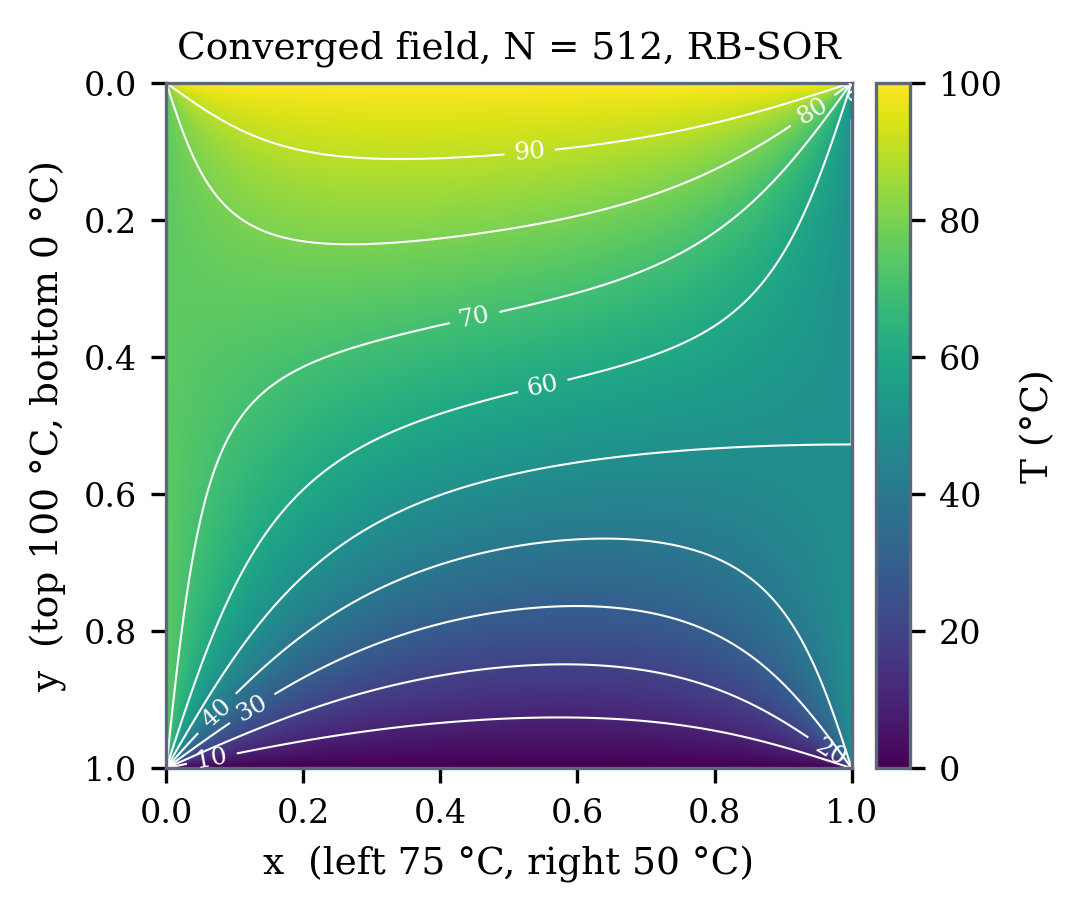

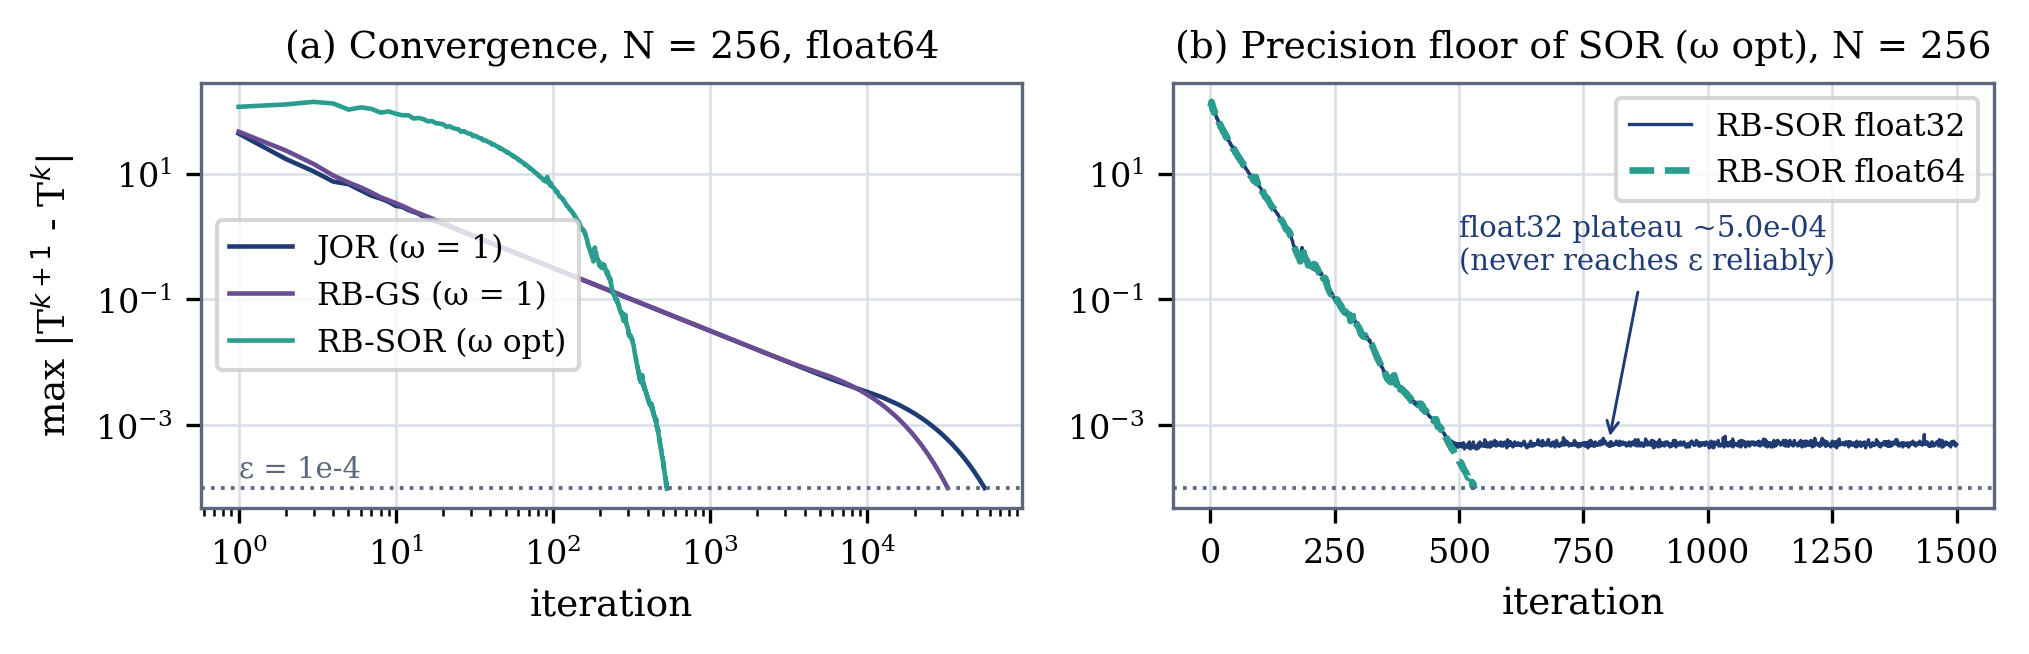

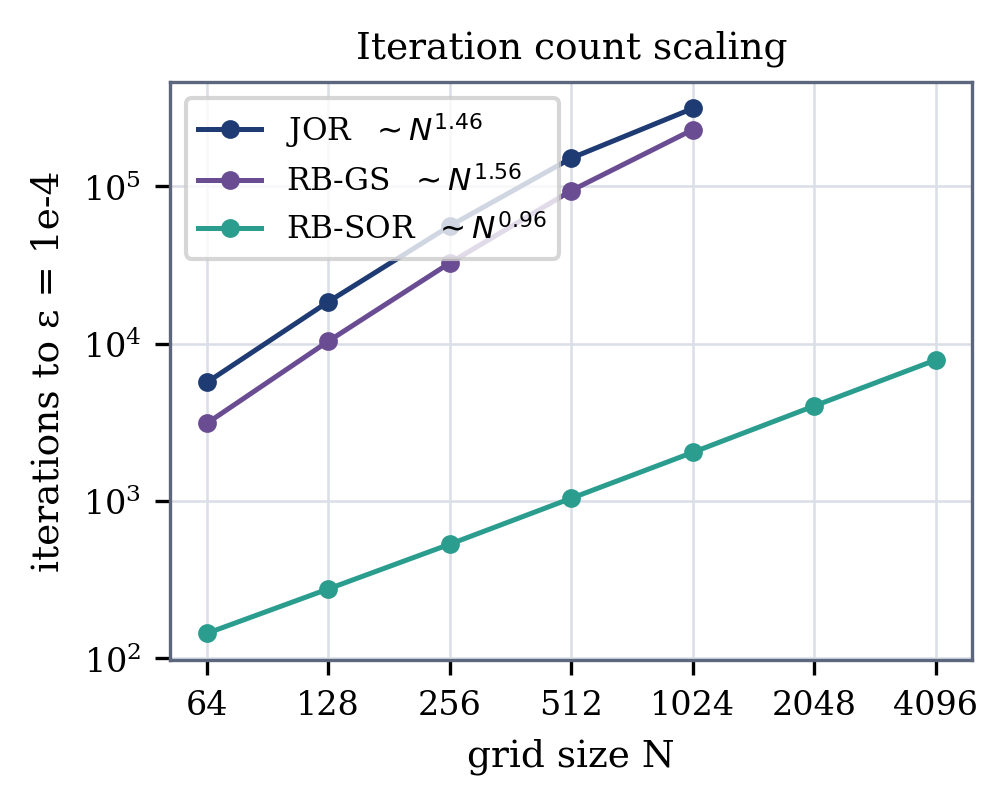

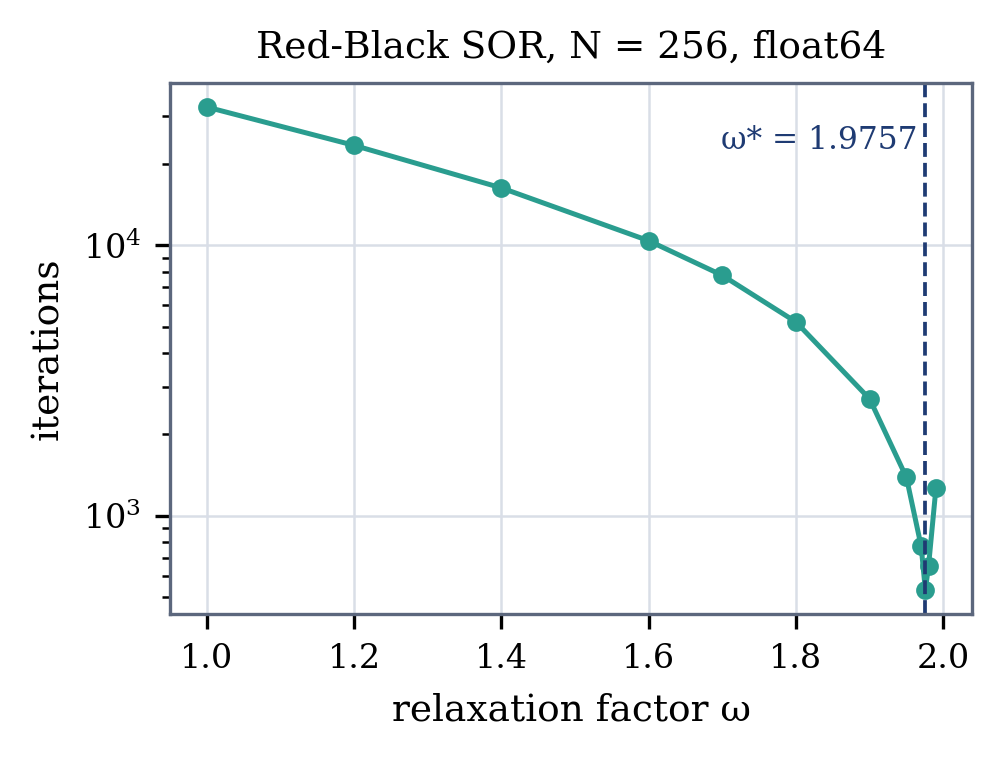

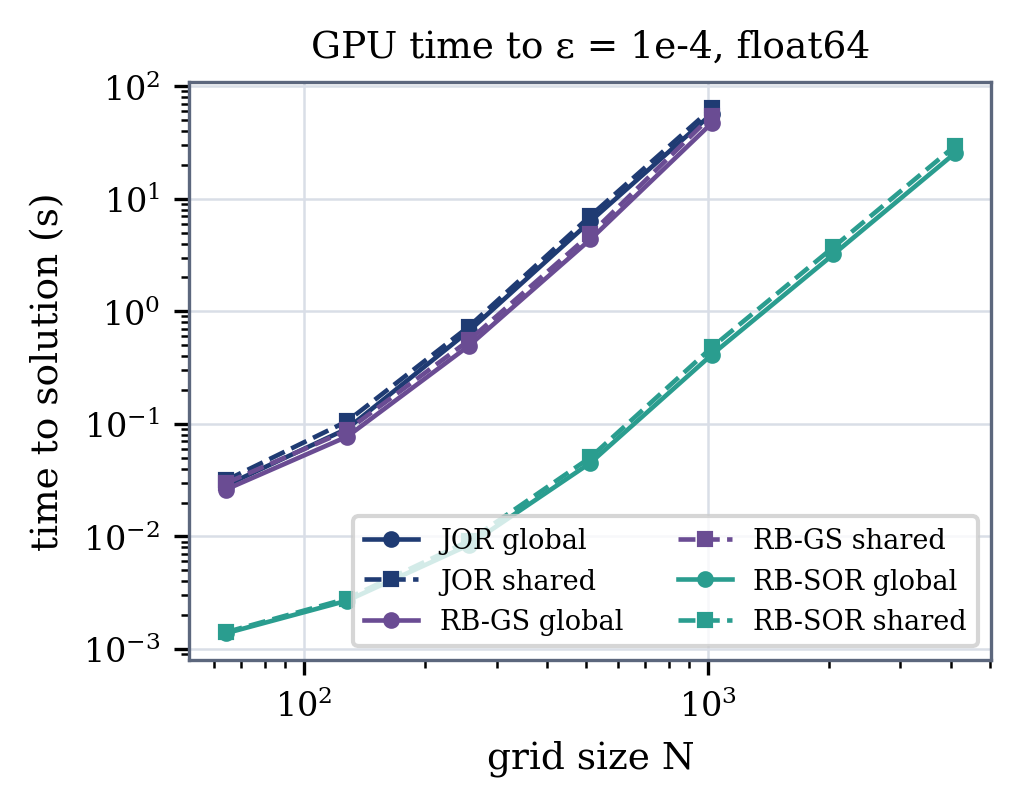

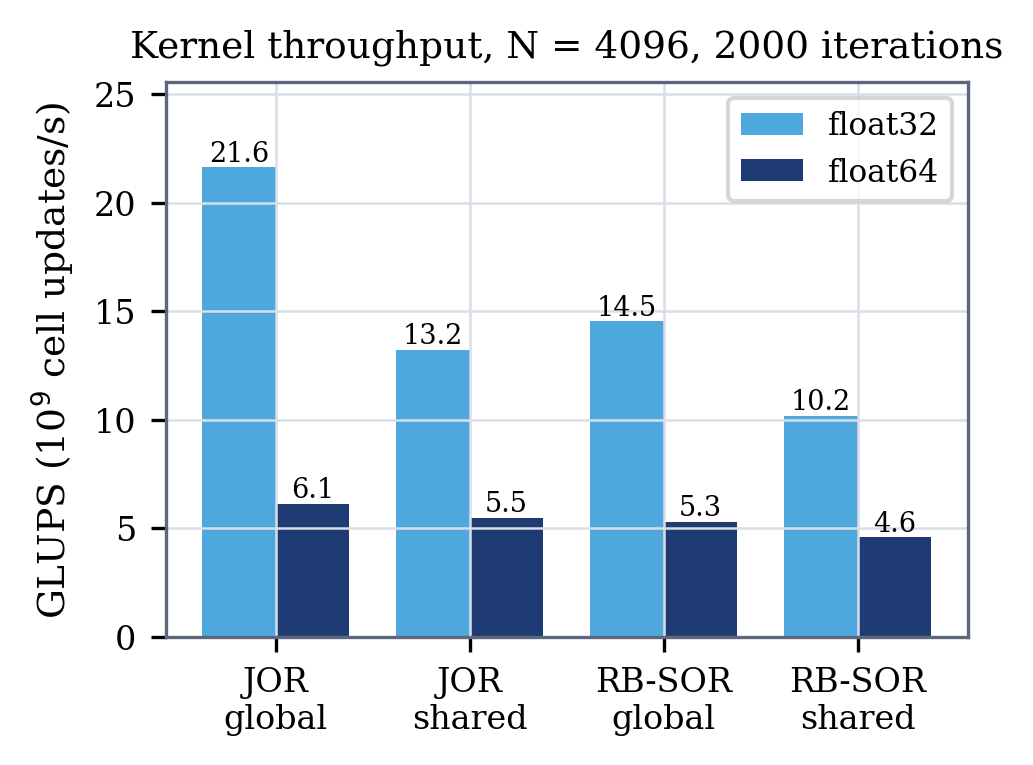

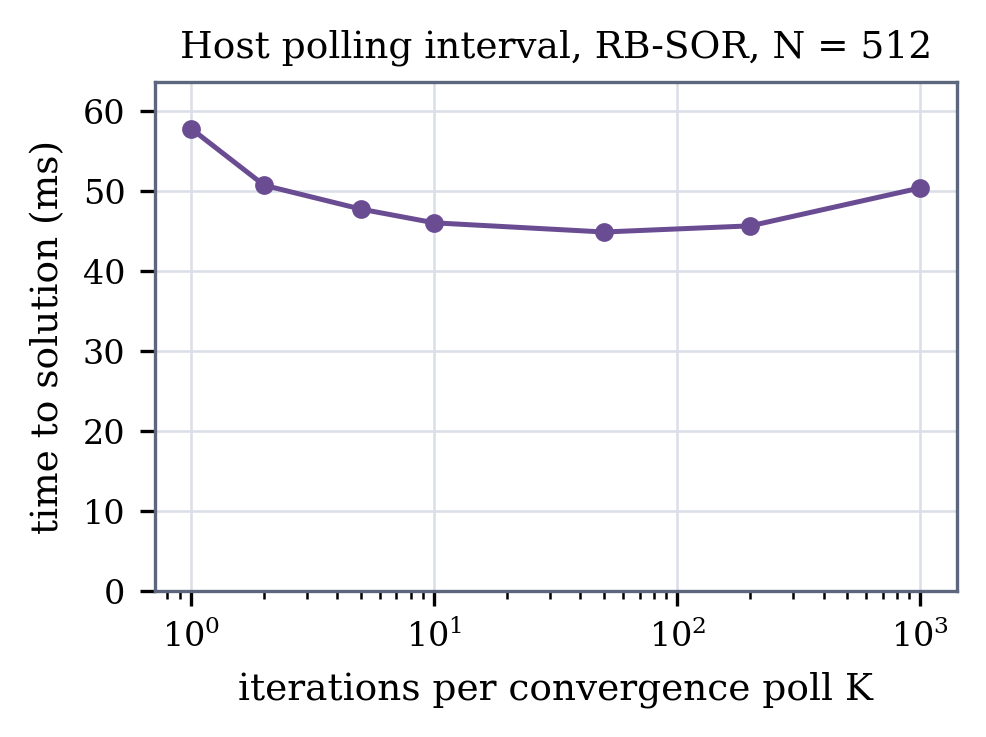

In [13]:
!python3 make_assets.py --data data --out assets
from IPython.display import Image, display
for f in ["fig_field", "fig_history", "fig_iters", "fig_omega", "fig_time", "fig_bw", "fig_batch"]:
    display(Image(f"assets/{f}.png", width=760 if f == "fig_history" else 470))

In [14]:
s = conv.pivot_table(index=["solver", "N"], columns="variant", values="kernel_ms")
s["global/shared"] = (s["global"] / s["shared"]).round(3)
s = s.join(conv[conv.variant == "global"].set_index(["solver", "N"])[["iters"]])
s = s.join(pd.read_csv("data/iters.csv").set_index(["solver", "N"])[["max_err"]])
display(s.round(3))
print(json.dumps(json.load(open("assets/numbers.json")), indent=1))

global     shared  global/shared   iters  max_err
solver N                                                         
JOR    64       28.316     31.394          0.902    5655    0.080
       128      90.692    105.573          0.859   18404    0.327
       256     666.578    730.559          0.912   55830    1.318
       512    6303.826   7032.945          0.896  150654    5.290
       1024  56922.465  63586.262          0.895  311637   21.007
RB-GS  64       26.041     29.665          0.878    3107    0.040
       128      77.122     87.517          0.881   10336    0.163
       256     492.993    550.582          0.895   32483    0.659
       512    4345.577   4839.008          0.898   93660    2.645
       1024  47076.414  54798.652          0.859  228375   10.585
RB-SOR 64        1.377      1.407          0.979     144    0.001
       128       2.690      2.802          0.960     276    0.002
       256       8.377      9.106          0.920     531    0.003
       512      44.957     50.274          0.894    1040    0.003
       1024    412.077    478.233          0.862    2035    0.004
       2048   3201.818   3714.959          0.862    4014      NaN
       4096  25382.936  29434.514          0.862    7869      NaN

{
 "Measured": "1",
 "Device": "Tesla T4",
 "GPUSource": "measured on the Colab Tesla T4",
 "SlopeJOR": "1.46",
 "SlopeRBGS": "1.56",
 "SlopeRBSOR": "0.96",
 "NRef": "512",
 "ItJOR": "150,654",
 "ItGS": "93,660",
 "ItSOR": "1,040",
 "SORvsJOR": "145",
 "GSvsJOR": "1.61",
 "ErrJOR": "5.29",
 "ErrSOR": "3.4e-03",
 "NJORLarge": "1024",
 "ErrJORLarge": "21.0",
 "NT": "1024",
 "TJOR": "56.92",
 "TSOR": "412.1",
 "TimeSpeedup": "138",
 "ShJORmin": "0.86",
 "ShJORmax": "0.91",
 "ShRBmin": "0.86",
 "ShRBmax": "0.90",
 "NBench": "4096",
 "BWJORd": "98",
 "BWJORf": "173",
 "GLUPSf": "21.6",
 "GLUPSd": "6.1",
 "BatchOne": "57.8",
 "BatchDef": "45.6",
 "BatchGain": "1.27",
 "OmegaN": "256",
 "OmegaBest": "1.9757",
 "OmegaBestIt": "531",
 "OmegaOneIt": "32,483"
}


## 11. Custom boundary conditions from a file
Any initial grid can be supplied; its outer ring is held fixed. Here: a sinusoidal top edge, a linear left edge,
a cold right edge and an interior initial guess of 20 degrees C.

,method,variant,N,omega,iters,kernel_ms,total_ms
0,rbsor,shared,384,1.983728,742,40.646,42.321


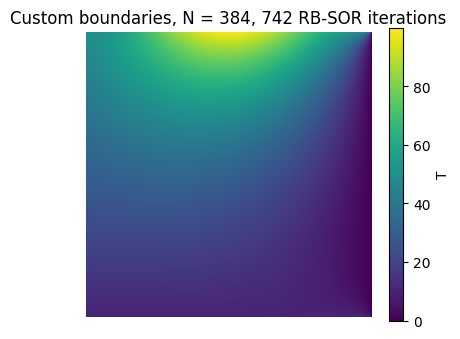

In [15]:
import matplotlib.pyplot as plt
N = 384
g = np.full((N, N), 20.0)
x = np.linspace(0, 1, N)
g[0, :] = 50 + 50 * np.sin(np.pi * x) ** 2
g[-1, :] = 10.0
g[:, 0] = np.linspace(g[0, 0], 10, N)
g[:, -1] = 0.0
g.tofile("custom_init.bin")
df, _ = run("-n", N, "-i", "custom_init.bin", "-m", "rbsor", "-v", "shared", "-o", "custom_out.bin")
display(df[["method", "variant", "N", "omega", "iters", "kernel_ms", "total_ms"]])
T = np.fromfile("custom_out.bin").reshape(N, N)
assert np.allclose(T[0], g[0]) and np.allclose(T[:, -1], g[:, -1]), "boundary must stay fixed"
fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(T, cmap="viridis"); fig.colorbar(im, ax=ax, label="T")
ax.set_title(f"Custom boundaries, N = {N}, {int(df.iters[0])} RB-SOR iterations"); ax.axis("off"); plt.show()

---
# Part B. Geometric Multigrid (GMG): the production solver

Part A showed that the best classic method, Red-Black SOR, still needs **O(N)** iterations: about 2,000 at $N=1025$ and 8,000 at $N=4097$.
Multigrid needs **3 cycles for every grid size**. This part explains why, step by step, and then runs it on the T4.

## 12. Why do Jacobi and Gauss-Seidel get slow?
Look at the *error* $e = T_{\text{exact}} - T_{\text{current}}$. Split it into waves:

* **wiggly (high-frequency) error**, which changes sign from cell to cell. One sweep averages each cell with its neighbours, so these waves die in 2 or 3 sweeps. The smoother is doing its job.
* **smooth (low-frequency) error**, which looks almost the same in neighbouring cells. Averaging hardly changes it. Information moves only **one cell per sweep**, so a wave that spans the whole plate needs about $N^2$ sweeps.

The cell below shows this in 1D with plain NumPy (no GPU needed).

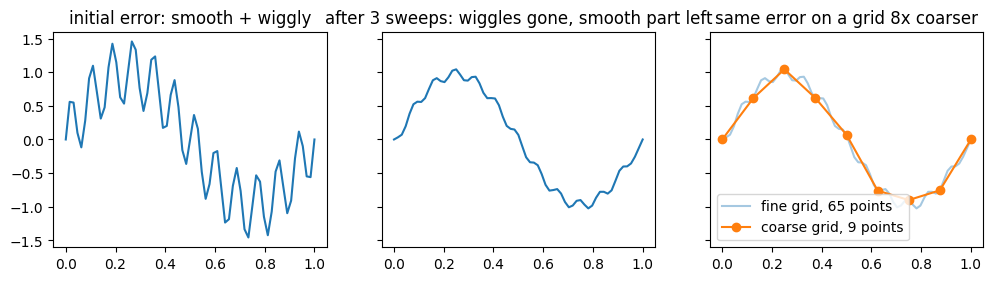

On the 9-point grid the remaining error spans only ~8 cells, so it counts as 'wiggly' there and is cheap to remove.


In [16]:
import numpy as np, matplotlib.pyplot as plt
n = 65; x = np.linspace(0, 1, n)
e0 = np.sin(2*np.pi*x) + 0.5*np.sin(24*np.pi*x); e0[[0, -1]] = 0

def gauss_seidel(e, sweeps):
    e = e.copy()
    for _ in range(sweeps):
        for i in range(1, n-1):
            e[i] = 0.5*(e[i-1] + e[i+1])
    return e

fig, ax = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
ax[0].plot(x, e0); ax[0].set_title("initial error: smooth + wiggly")
ax[1].plot(x, gauss_seidel(e0, 3)); ax[1].set_title("after 3 sweeps: wiggles gone, smooth part left")
e3 = gauss_seidel(e0, 3)
ax[2].plot(x, e3, alpha=.4, label="fine grid, 65 points"); ax[2].plot(x[::8], e3[::8], "o-", label="coarse grid, 9 points")
ax[2].set_title("same error on a grid 8x coarser"); ax[2].legend(); plt.show()
print("On the 9-point grid the remaining error spans only ~8 cells, so it counts as 'wiggly' there and is cheap to remove.")

## 13. The multigrid idea in four steps
1. **Smooth.** Do a few Gauss-Seidel sweeps on the fine grid; the wiggly error disappears.
2. **Restrict.** Compute the residual $r = f - A u$ (what is still "wrong") and move it to a grid with half the points in each direction.
3. **Solve on the coarse grid** for the correction $e$ in $A_{2h} e = r_{2h}$. Do the *same* thing there (recursion), down to a $3\times3$ grid with 1 unknown.
4. **Prolongate and correct.** Interpolate $e$ back to the fine grid, add it to $u$, and smooth again to remove the small wiggles the interpolation creates.

That path, down to the coarsest grid and back up, is a **V-cycle**. Each grid level costs 1/4 of the one above it, so a whole V-cycle costs about $4/3$ of the work on the finest grid alone.

| Component | Our choice | Formula / stencil |
|---|---|---|
| Smoother | Red-Black Gauss-Seidel, $\nu_1=2$ before, $\nu_2=2$ after | $u_{ij} = \tfrac14(\text{4 neighbours} + h^2 f_{ij})$ |
| Residual | 5-point | $r = f - (4u_{ij}-\sum \text{nbrs})/h^2$ |
| Restriction $R$ | full weighting | $\tfrac1{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$ |
| Prolongation $P$ | bilinear interpolation | average of the 1, 2 or 4 nearest coarse points |
| Coarsest grid | $3\times3$ (1 unknown) | one sweep solves it exactly |
| Start | Full Multigrid (FMG) | solve coarse first, interpolate up, one V-cycle per level |

**Grid sizes.** A coarse point sits on every second fine point, so $N-1$ must stay even on every level: $N = 2^k+1$ (129, 257, 513, 1025, 2049, 4097).

**Stopping rule.** It is the same as the assignment: stop when $\max|T^{new}-T^{old}| < \varepsilon$, where one "iteration" is now one cycle. Because each cycle shrinks the error about 25-fold, this rule is also an honest error estimate: error $\approx$ change $\times \rho/(1-\rho) \approx 0.04\times$ change. For JOR the same rule left an error of several degrees.

## 14. GPU implementation (`gmg.cu`)
* **8 small kernels:** `k_smooth_rb`, `k_residual`, `k_restrict`, `k_prolong_add`, `k_fmg_down`, `k_fmg_interp`, `k_stats` and `k_finalize`. Each is one coalesced pass over one grid level.
* **Convergence on the device:** `k_stats` reduces $\max|u-u_{prev}|$ and the residual with warp shuffles and one `atomicMax` per block. `k_finalize` (1 thread) records the values and sets a **stop flag**. Every kernel starts with `if (stop) return;`, so cycles that were already queued cost almost nothing.
* **CUDA Graph:** one V-cycle at $N=1025$ is about 100 kernel launches, and most of them are on tiny grids, where launch overhead dominates. The cycle is captured once as a graph and replayed (`--no-graph` turns this off for comparison).
* **Transfers:** the grid is copied to the GPU once and back once. The host reads 8 bytes (stop flag and cycle count) every 2 cycles.
* **Production features:** input validation, exit code 0 (converged), 2 (not converged) or 3 (diverged/NaN), a `--verify` check against a sequential CPU implementation of the same algorithm, an optional heat source `-s Q`, user boundary files, and float64 by default.

In [17]:
%%writefile gmg.cu
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <cmath>
#include <string>
#include <vector>
#include <chrono>
#include <algorithm>
#include <functional>
#include <cuda_runtime.h>

#define CUDA_CHECK(call)                                                        \
    do {                                                                        \
        cudaError_t err_ = (call);                                              \
        if (err_ != cudaSuccess) {                                              \
            fprintf(stderr, "CUDA error %s at %s:%d\n",                         \
                    cudaGetErrorString(err_), __FILE__, __LINE__);              \
            exit(EXIT_FAILURE);                                                 \
        }                                                                       \
    } while (0)

constexpr int BX = 32;
constexpr int BY = 8;

struct Ctrl { int stop; int cycle; };

template <typename real> __device__ __forceinline__ real dAbs(real x) { return x < real(0) ? -x : x; }
template <typename real> __device__ __forceinline__ real dMax(real a, real b) { return a > b ? a : b; }

template <typename real>
__device__ __forceinline__ real warpMax(real v) {
#pragma unroll
    for (int off = 16; off > 0; off >>= 1)
        v = dMax(v, __shfl_down_sync(0xffffffffu, v, off));
    return v;
}

__device__ __forceinline__ void atomicMaxNonNeg(float* dst, float v) {
    atomicMax(reinterpret_cast<int*>(dst), __float_as_int(v));
}
__device__ __forceinline__ void atomicMaxNonNeg(double* dst, double v) {
    atomicMax(reinterpret_cast<unsigned long long*>(dst),
              (unsigned long long)__double_as_longlong(v));
}

template <typename real>
__global__ void k_smooth_rb(real* __restrict__ u, const real* __restrict__ f, int n,
                            real h2, real w, int color, const Ctrl* ctrl) {
    if (ctrl->stop) return;
    const int tx = blockIdx.x * blockDim.x + threadIdx.x;
    const int i  = blockIdx.y * blockDim.y + threadIdx.y;
    const int j  = 2 * tx + ((i + color) & 1);
    if (i > 0 && i < n - 1 && j > 0 && j < n - 1) {
        const size_t id = (size_t)i * n + j;
        const real gs  = real(0.25) * (u[id - n] + u[id + n] + u[id - 1] + u[id + 1] + h2 * f[id]);
        const real old = u[id];
        u[id] = old + w * (gs - old);
    }
}

template <typename real>
__global__ void k_residual(const real* __restrict__ u, const real* __restrict__ f,
                           real* __restrict__ r, int n, real invh2, const Ctrl* ctrl) {
    if (ctrl->stop) return;
    const int j = blockIdx.x * blockDim.x + threadIdx.x;
    const int i = blockIdx.y * blockDim.y + threadIdx.y;
    if (i >= n || j >= n) return;
    const size_t id = (size_t)i * n + j;
    if (i > 0 && i < n - 1 && j > 0 && j < n - 1)
        r[id] = f[id] - (real(4) * u[id] - (u[id - n] + u[id + n] + u[id - 1] + u[id + 1])) * invh2;
    else
        r[id] = real(0);
}

template <typename real>
__device__ __forceinline__ real fullWeight(const real* a, size_t id, int nf) {
    const real c = a[id];
    const real e = a[id - 1] + a[id + 1] + a[id - nf] + a[id + nf];
    const real d = a[id - nf - 1] + a[id - nf + 1] + a[id + nf - 1] + a[id + nf + 1];
    return (real(4) * c + real(2) * e + d) * real(0.0625);
}

template <typename real>
__global__ void k_restrict(const real* __restrict__ rf, int nf,
                           real* __restrict__ fc, real* __restrict__ uc, int nc,
                           const Ctrl* ctrl) {
    if (ctrl->stop) return;
    const int J = blockIdx.x * blockDim.x + threadIdx.x;
    const int I = blockIdx.y * blockDim.y + threadIdx.y;
    if (I >= nc || J >= nc) return;
    const size_t ic = (size_t)I * nc + J;
    if (I > 0 && I < nc - 1 && J > 0 && J < nc - 1)
        fc[ic] = fullWeight(rf, (size_t)(2 * I) * nf + 2 * J, nf);
    else
        fc[ic] = real(0);
    uc[ic] = real(0);
}

template <typename real>
__device__ __forceinline__ real bilinear(const real* uc, int nc, int i, int j) {
    const int I = i >> 1, J = j >> 1;
    const real* p = uc + (size_t)I * nc + J;
    if (!(i & 1) && !(j & 1)) return p[0];
    if ( (i & 1) && !(j & 1)) return real(0.5)  * (p[0] + p[nc]);
    if (!(i & 1) &&  (j & 1)) return real(0.5)  * (p[0] + p[1]);
    return real(0.25) * (p[0] + p[1] + p[nc] + p[nc + 1]);
}

template <typename real>
__global__ void k_prolong_add(real* __restrict__ uf, int nf, const real* __restrict__ uc,
                              int nc, const Ctrl* ctrl) {
    if (ctrl->stop) return;
    const int j = blockIdx.x * blockDim.x + threadIdx.x;
    const int i = blockIdx.y * blockDim.y + threadIdx.y;
    if (i > 0 && i < nf - 1 && j > 0 && j < nf - 1)
        uf[(size_t)i * nf + j] += bilinear(uc, nc, i, j);
}

template <typename real>
__global__ void k_fmg_down(const real* __restrict__ uf, const real* __restrict__ ff, int nf,
                           real* __restrict__ uc, real* __restrict__ fc, int nc) {
    const int J = blockIdx.x * blockDim.x + threadIdx.x;
    const int I = blockIdx.y * blockDim.y + threadIdx.y;
    if (I >= nc || J >= nc) return;
    const size_t ic = (size_t)I * nc + J, iff = (size_t)(2 * I) * nf + 2 * J;
    if (I > 0 && I < nc - 1 && J > 0 && J < nc - 1) { uc[ic] = real(0); fc[ic] = fullWeight(ff, iff, nf); }
    else                                           { uc[ic] = uf[iff]; fc[ic] = real(0); }
}

template <typename real>
__global__ void k_fmg_interp(real* __restrict__ uf, int nf, const real* __restrict__ uc, int nc) {
    const int j = blockIdx.x * blockDim.x + threadIdx.x;
    const int i = blockIdx.y * blockDim.y + threadIdx.y;
    if (i > 0 && i < nf - 1 && j > 0 && j < nf - 1)
        uf[(size_t)i * nf + j] = bilinear(uc, nc, i, j);
}

template <typename real>
__global__ void k_stats(const real* __restrict__ u, real* __restrict__ uprev,
                        const real* __restrict__ f, int n, real h2, real* acc,
                        const Ctrl* ctrl) {
    if (ctrl->stop) return;
    const int j = blockIdx.x * blockDim.x + threadIdx.x;
    const int i = blockIdx.y * blockDim.y + threadIdx.y;
    real d = 0, r = 0;
    if (i > 0 && i < n - 1 && j > 0 && j < n - 1) {
        const size_t id = (size_t)i * n + j;
        const real c = u[id];
        d = dAbs(c - uprev[id]);
        uprev[id] = c;
        r = real(0.25) * dAbs(u[id - n] + u[id + n] + u[id - 1] + u[id + 1] + h2 * f[id] - real(4) * c);
    }

    __shared__ real sd[32], sr[32];
    const int tid = threadIdx.y * blockDim.x + threadIdx.x, lane = tid & 31, wid = tid >> 5;
    const int nW  = (blockDim.x * blockDim.y + 31) >> 5;
    d = warpMax(d); r = warpMax(r);
    if (lane == 0) { sd[wid] = d; sr[wid] = r; }
    __syncthreads();
    if (wid == 0) {
        d = (lane < nW) ? sd[lane] : real(0);
        r = (lane < nW) ? sr[lane] : real(0);
        d = warpMax(d); r = warpMax(r);
        if (lane == 0) {
            if (d > real(0)) atomicMaxNonNeg(&acc[0], d);
            if (r > real(0)) atomicMaxNonNeg(&acc[1], r);
        }
    }
}

template <typename real>
__global__ void k_finalize(real* acc, real* histDiff, real* histRes, Ctrl* ctrl,
                           real eps, int critRes, int maxCycles) {
    if (ctrl->stop) return;
    const int c = ctrl->cycle;
    const real d = acc[0], r = acc[1];
    histDiff[c] = d; histRes[c] = r;
    acc[0] = real(0); acc[1] = real(0);
    ctrl->cycle = c + 1;
    const real m = critRes ? r : d;
    if (!(d < real(1e30)))      ctrl->stop = 3;
    else if (m < eps)           ctrl->stop = 1;
    else if (c + 1 >= maxCycles) ctrl->stop = 2;
}

struct Config {
    int    N = 513;
    double eps = 1e-4;
    double source = 0.0;
    std::string cycle = "V";
    int    nu1 = 2, nu2 = 2;
    int    maxLevels = 64;
    int    coarseSweeps = -1;
    int    maxCycles = 200;
    int    batch = 2;
    bool   fmg = true, graph = true;
    std::string crit = "diff";
    std::string precision = "double";
    double top = 100, bottom = 0, left = 75, right = 50, init = 0;
    std::string inFile, outFile, histFile;
    bool   verify = false, quiet = false;
};

struct Result {
    int levels = 0, coarsest = 0, cycles = 0, stop = 0;
    double fmgMs = 0, solveMs = 0, totalMs = 0, rho = 0;
    std::vector<double> grid, hd, hr;
    std::vector<int> sizes;
};

static inline dim3 gridPts(int n) { return dim3((n + BX - 1) / BX, (n + BY - 1) / BY); }
static inline dim3 gridRB(int n)  { return dim3(((n + 1) / 2 + BX - 1) / BX, (n + BY - 1) / BY); }

static std::vector<int> hierarchy(int N, int maxLevels) {
    std::vector<int> s{N};
    while ((int)s.size() < maxLevels && s.back() > 3 && (s.back() - 1) % 2 == 0)
        s.push_back((s.back() - 1) / 2 + 1);
    return s;
}
static double sorOmega(int n) {
    const double PI = 3.14159265358979323846;
    return n <= 3 ? 1.0 : 2.0 / (1.0 + std::sin(PI / (double)(n - 1)));
}
static int autoCoarseSweeps(int n) { return n <= 3 ? 1 : std::max(4, 2 * n); }

static void buildInitialGrid(const Config& c, std::vector<double>& g) {
    const int N = c.N;
    g.assign((size_t)N * N, c.init);
    if (!c.inFile.empty()) {
        FILE* fp = fopen(c.inFile.c_str(), "rb");
        if (!fp) { fprintf(stderr, "cannot open %s\n", c.inFile.c_str()); exit(1); }
        const size_t got = fread(g.data(), sizeof(double), g.size(), fp);
        fclose(fp);
        if (got != g.size()) { fprintf(stderr, "init file must hold N*N float64\n"); exit(1); }
        return;
    }
    for (int j = 0; j < N; ++j) { g[j] = c.top; g[(size_t)(N - 1) * N + j] = c.bottom; }
    for (int i = 1; i < N - 1; ++i) { g[(size_t)i * N] = c.left; g[(size_t)i * N + N - 1] = c.right; }
}

template <typename real>
class GpuGMG {
public:
    struct Level { int n; real h2, invh2; real *u, *f, *r; };

    GpuGMG(const Config& c, cudaStream_t s) : cfg(c), st(s) {
        sizes = hierarchy(c.N, c.maxLevels);
        const double h = 1.0 / (c.N - 1);
        for (size_t l = 0; l < sizes.size(); ++l) {
            Level L; L.n = sizes[l];
            const double hl = h * (double)(1 << l);
            L.h2 = (real)(hl * hl); L.invh2 = (real)(1.0 / (hl * hl));
            const size_t b = (size_t)L.n * L.n * sizeof(real);
            CUDA_CHECK(cudaMalloc(&L.u, b)); CUDA_CHECK(cudaMalloc(&L.f, b)); CUDA_CHECK(cudaMalloc(&L.r, b));
            CUDA_CHECK(cudaMemset(L.u, 0, b)); CUDA_CHECK(cudaMemset(L.f, 0, b)); CUDA_CHECK(cudaMemset(L.r, 0, b));
            lv.push_back(L);
        }
        const size_t b0 = (size_t)c.N * c.N * sizeof(real);
        CUDA_CHECK(cudaMalloc(&uprev, b0));
        CUDA_CHECK(cudaMalloc(&acc, 2 * sizeof(real)));
        CUDA_CHECK(cudaMalloc(&hd, (size_t)c.maxCycles * sizeof(real)));
        CUDA_CHECK(cudaMalloc(&hr, (size_t)c.maxCycles * sizeof(real)));
        CUDA_CHECK(cudaMalloc(&ctrl, sizeof(Ctrl)));
        CUDA_CHECK(cudaMemset(acc, 0, 2 * sizeof(real)));
        CUDA_CHECK(cudaMemset(ctrl, 0, sizeof(Ctrl)));
        coarseSweeps = c.coarseSweeps > 0 ? c.coarseSweeps : autoCoarseSweeps(sizes.back());
        coarseW = (real)sorOmega(sizes.back());
    }
    ~GpuGMG() {
        for (auto& L : lv) { cudaFree(L.u); cudaFree(L.f); cudaFree(L.r); }
        cudaFree(uprev); cudaFree(acc); cudaFree(hd); cudaFree(hr); cudaFree(ctrl);
        if (gexec) cudaGraphExecDestroy(gexec);
        if (graph) cudaGraphDestroy(graph);
    }

    void upload(const std::vector<double>& g0) {
        std::vector<real> g(g0.begin(), g0.end());
        const size_t b = g.size() * sizeof(real);
        CUDA_CHECK(cudaMemcpy(lv[0].u, g.data(), b, cudaMemcpyHostToDevice));
        if (cfg.source != 0.0) {
            std::vector<real> f(g.size(), (real)cfg.source);
            CUDA_CHECK(cudaMemcpy(lv[0].f, f.data(), b, cudaMemcpyHostToDevice));
        }
    }

    void smooth(int l, int sweeps, real w) {
        const Level& L = lv[l];
        for (int s = 0; s < sweeps; ++s)
            for (int color = 0; color < 2; ++color)
                k_smooth_rb<real><<<gridRB(L.n), dim3(BX, BY), 0, st>>>(L.u, L.f, L.n, L.h2, w, color, ctrl);
    }

    void cycle(int l) {
        const int last = (int)lv.size() - 1;
        if (l == last) { smooth(l, coarseSweeps, coarseW); return; }
        const Level& F = lv[l]; const Level& C = lv[l + 1];
        smooth(l, cfg.nu1, real(1));
        k_residual<real><<<gridPts(F.n), dim3(BX, BY), 0, st>>>(F.u, F.f, F.r, F.n, F.invh2, ctrl);
        k_restrict<real><<<gridPts(C.n), dim3(BX, BY), 0, st>>>(F.r, F.n, C.f, C.u, C.n, ctrl);
        const int gamma = (cfg.cycle == "W") ? 2 : 1;
        for (int g = 0; g < gamma; ++g) cycle(l + 1);
        k_prolong_add<real><<<gridPts(F.n), dim3(BX, BY), 0, st>>>(F.u, F.n, C.u, C.n, ctrl);
        smooth(l, cfg.nu2, real(1));
    }

    void enqueueIteration() {
        cycle(0);
        const Level& F = lv[0];
        k_stats<real><<<gridPts(F.n), dim3(BX, BY), 0, st>>>(F.u, uprev, F.f, F.n, F.h2, acc, ctrl);
        k_finalize<real><<<1, 1, 0, st>>>(acc, hd, hr, ctrl, (real)cfg.eps, cfg.crit == "res" ? 1 : 0, cfg.maxCycles);
    }

    void fmg() {
        const int last = (int)lv.size() - 1;
        for (int l = 0; l < last; ++l)
            k_fmg_down<real><<<gridPts(lv[l + 1].n), dim3(BX, BY), 0, st>>>(lv[l].u, lv[l].f, lv[l].n,
                                                                          lv[l + 1].u, lv[l + 1].f, lv[l + 1].n);
        smooth(last, coarseSweeps, coarseW);
        for (int l = last; l > 0; --l) {
            k_fmg_interp<real><<<gridPts(lv[l - 1].n), dim3(BX, BY), 0, st>>>(lv[l - 1].u, lv[l - 1].n, lv[l].u, lv[l].n);
            cycle(l - 1);
        }
    }

    Result solve() {
        Result R; R.sizes = sizes; R.levels = (int)sizes.size(); R.coarsest = sizes.back();
        const size_t b0 = (size_t)cfg.N * cfg.N * sizeof(real);
        cudaEvent_t e0, e1, e2;
        CUDA_CHECK(cudaEventCreate(&e0)); CUDA_CHECK(cudaEventCreate(&e1)); CUDA_CHECK(cudaEventCreate(&e2));
        CUDA_CHECK(cudaEventRecord(e0, st));
        if (cfg.fmg && lv.size() > 1) fmg();
        CUDA_CHECK(cudaMemcpyAsync(uprev, lv[0].u, b0, cudaMemcpyDeviceToDevice, st));
        CUDA_CHECK(cudaEventRecord(e1, st));

        if (cfg.graph) {
            CUDA_CHECK(cudaStreamBeginCapture(st, cudaStreamCaptureModeThreadLocal));
            enqueueIteration();
            CUDA_CHECK(cudaStreamEndCapture(st, &graph));
            CUDA_CHECK(cudaGraphInstantiateWithFlags(&gexec, graph, 0));
        }
        Ctrl h{0, 0};
        while (h.stop == 0) {
            for (int k = 0; k < cfg.batch; ++k) {
                if (cfg.graph) CUDA_CHECK(cudaGraphLaunch(gexec, st));
                else           enqueueIteration();
            }
            CUDA_CHECK(cudaGetLastError());
            CUDA_CHECK(cudaMemcpyAsync(&h, ctrl, sizeof(Ctrl), cudaMemcpyDeviceToHost, st));
            CUDA_CHECK(cudaStreamSynchronize(st));
        }
        CUDA_CHECK(cudaEventRecord(e2, st));
        CUDA_CHECK(cudaEventSynchronize(e2));
        float a = 0, b = 0;
        CUDA_CHECK(cudaEventElapsedTime(&a, e0, e1)); CUDA_CHECK(cudaEventElapsedTime(&b, e0, e2));
        R.fmgMs = a; R.solveMs = b; R.cycles = h.cycle; R.stop = h.stop;

        std::vector<real> g((size_t)cfg.N * cfg.N), d(h.cycle), r(h.cycle);
        CUDA_CHECK(cudaMemcpy(g.data(), lv[0].u, b0, cudaMemcpyDeviceToHost));
        if (h.cycle) {
            CUDA_CHECK(cudaMemcpy(d.data(), hd, h.cycle * sizeof(real), cudaMemcpyDeviceToHost));
            CUDA_CHECK(cudaMemcpy(r.data(), hr, h.cycle * sizeof(real), cudaMemcpyDeviceToHost));
        }
        R.grid.assign(g.begin(), g.end()); R.hd.assign(d.begin(), d.end()); R.hr.assign(r.begin(), r.end());
        cudaEventDestroy(e0); cudaEventDestroy(e1); cudaEventDestroy(e2);
        return R;
    }

    std::vector<int> sizes;
private:
    const Config& cfg;
    cudaStream_t st;
    std::vector<Level> lv;
    real *uprev = nullptr, *acc = nullptr, *hd = nullptr, *hr = nullptr;
    Ctrl* ctrl = nullptr;
    int coarseSweeps = 1;
    real coarseW = 1;
    cudaGraph_t graph = nullptr;
    cudaGraphExec_t gexec = nullptr;
};

template <typename real>
static Result cpuGMG(const Config& c, const std::vector<double>& g0) {
    struct L { int n; real h2, invh2; std::vector<real> u, f, r; };
    Result R; R.sizes = hierarchy(c.N, c.maxLevels); R.levels = (int)R.sizes.size(); R.coarsest = R.sizes.back();
    std::vector<L> lv;
    const double h = 1.0 / (c.N - 1);
    for (size_t l = 0; l < R.sizes.size(); ++l) {
        L x; x.n = R.sizes[l]; const double hl = h * (double)(1 << l);
        x.h2 = (real)(hl * hl); x.invh2 = (real)(1.0 / (hl * hl));
        x.u.assign((size_t)x.n * x.n, 0); x.f = x.u; x.r = x.u; lv.push_back(x);
    }
    for (size_t k = 0; k < g0.size(); ++k) lv[0].u[k] = (real)g0[k];
    if (c.source != 0.0) std::fill(lv[0].f.begin(), lv[0].f.end(), (real)c.source);
    const int last = (int)lv.size() - 1;
    const int cs = c.coarseSweeps > 0 ? c.coarseSweeps : autoCoarseSweeps(lv[last].n);
    const real cw = (real)sorOmega(lv[last].n);
    auto smooth = [&](int l, int sweeps, real w) {
        L& a = lv[l]; const int n = a.n;
        for (int s = 0; s < sweeps; ++s) for (int color = 0; color < 2; ++color)
            for (int i = 1; i < n - 1; ++i) for (int j = 1 + ((i + color + 1) & 1); j < n - 1; j += 2) {
                const size_t id = (size_t)i * n + j;
                const real gs = real(0.25) * (a.u[id - n] + a.u[id + n] + a.u[id - 1] + a.u[id + 1] + a.h2 * a.f[id]);
                const real old = a.u[id];
                a.u[id] = old + w * (gs - old);
            }
    };
    auto fw = [](const std::vector<real>& a, size_t id, int nf) {
        const real cc = a[id];
        const real e = a[id - 1] + a[id + 1] + a[id - nf] + a[id + nf];
        const real d = a[id - nf - 1] + a[id - nf + 1] + a[id + nf - 1] + a[id + nf + 1];
        return (real(4) * cc + real(2) * e + d) * real(0.0625);
    };
    auto bil = [](const std::vector<real>& uc, int nc, int i, int j) {
        const int I = i >> 1, J = j >> 1; const real* p = uc.data() + (size_t)I * nc + J;
        if (!(i & 1) && !(j & 1)) return p[0];
        if ((i & 1) && !(j & 1)) return real(0.5) * (p[0] + p[nc]);
        if (!(i & 1) && (j & 1)) return real(0.5) * (p[0] + p[1]);
        return real(0.25) * (p[0] + p[1] + p[nc] + p[nc + 1]);
    };
    std::function<void(int)> cyc = [&](int l) {
        if (l == last) { smooth(l, cs, cw); return; }
        L& F = lv[l]; L& C = lv[l + 1]; const int n = F.n, nc = C.n;
        smooth(l, c.nu1, real(1));
        for (int i = 0; i < n; ++i) for (int j = 0; j < n; ++j) {
            const size_t id = (size_t)i * n + j;
            F.r[id] = (i > 0 && i < n - 1 && j > 0 && j < n - 1)
                ? F.f[id] - (real(4) * F.u[id] - (F.u[id - n] + F.u[id + n] + F.u[id - 1] + F.u[id + 1])) * F.invh2 : real(0);
        }
        for (int I = 0; I < nc; ++I) for (int J = 0; J < nc; ++J) {
            const size_t ic = (size_t)I * nc + J;
            C.f[ic] = (I > 0 && I < nc - 1 && J > 0 && J < nc - 1) ? fw(F.r, (size_t)(2 * I) * n + 2 * J, n) : real(0);
            C.u[ic] = 0;
        }
        for (int g = 0; g < (c.cycle == "W" ? 2 : 1); ++g) cyc(l + 1);
        for (int i = 1; i < n - 1; ++i) for (int j = 1; j < n - 1; ++j) F.u[(size_t)i * n + j] += bil(C.u, nc, i, j);
        smooth(l, c.nu2, real(1));
    };
    auto t0 = std::chrono::high_resolution_clock::now();
    if (c.fmg && last > 0) {
        for (int l = 0; l < last; ++l) {
            L& F = lv[l]; L& C = lv[l + 1]; const int n = F.n, nc = C.n;
            for (int I = 0; I < nc; ++I) for (int J = 0; J < nc; ++J) {
                const size_t ic = (size_t)I * nc + J, iff = (size_t)(2 * I) * n + 2 * J;
                if (I > 0 && I < nc - 1 && J > 0 && J < nc - 1) { C.u[ic] = 0; C.f[ic] = fw(F.f, iff, n); }
                else { C.u[ic] = F.u[iff]; C.f[ic] = 0; }
            }
        }
        smooth(last, cs, cw);
        for (int l = last; l > 0; --l) {
            L& F = lv[l - 1]; L& C = lv[l];
            for (int i = 1; i < F.n - 1; ++i) for (int j = 1; j < F.n - 1; ++j) F.u[(size_t)i * F.n + j] = bil(C.u, C.n, i, j);
            cyc(l - 1);
        }
    }
    std::vector<real> up = lv[0].u;
    const int n = c.N;
    for (int k = 0; k < c.maxCycles; ++k) {
        cyc(0);
        real d = 0, r = 0;
        const std::vector<real>& u = lv[0].u; const std::vector<real>& f = lv[0].f;
        for (int i = 1; i < n - 1; ++i) for (int j = 1; j < n - 1; ++j) {
            const size_t id = (size_t)i * n + j; const real cc = u[id];
            const real dd = cc - up[id]; d = std::max(d, dd < 0 ? -dd : dd); up[id] = cc;
            const real rr = u[id - n] + u[id + n] + u[id - 1] + u[id + 1] + lv[0].h2 * f[id] - real(4) * cc;
            r = std::max(r, real(0.25) * (rr < 0 ? -rr : rr));
        }
        R.hd.push_back(d); R.hr.push_back(r); R.cycles = k + 1;
        const real m = c.crit == "res" ? r : d;
        if (!(d < real(1e30))) { R.stop = 3; break; }
        if (m < (real)c.eps) { R.stop = 1; break; }
        if (k + 1 >= c.maxCycles) R.stop = 2;
    }
    R.solveMs = std::chrono::duration<double, std::milli>(std::chrono::high_resolution_clock::now() - t0).count();
    R.grid.assign(lv[0].u.begin(), lv[0].u.end());
    return R;
}

static double convFactor(const std::vector<double>& hr) {
    if (hr.size() < 3 || hr[0] <= 0 || hr.back() <= 0) return 0.0;
    const size_t a = 1, b = hr.size() - 1;
    return std::pow(hr[b] / hr[a], 1.0 / (double)(b - a));
}

static void usage(const char* p) {
    printf("usage: %s [-n N] [-e eps] [-c V|W] [--nu1 k] [--nu2 k] [-p double|float]\n"
           "          [--levels L] [--coarse-sweeps k] [--maxcycles M] [--batch K]\n"
           "          [--no-fmg] [--no-graph] [--crit diff|res] [-s Q]\n"
           "          [-i init.bin] [-o out.bin] [--hist hist.csv]\n"
           "          [--top T --bottom T --left T --right T --init T] [--verify] [-q]\n"
           "  N = 2^k + 1 gives the full grid hierarchy (129, 257, 513, 1025, 2049, 4097)\n"
           "  init.bin / out.bin: raw N*N float64, row-major; edges of init.bin = fixed BCs\n", p);
}

template <typename real>
static int runAll(const Config& c, const std::vector<double>& h0, const cudaDeviceProp& prop) {
    cudaStream_t st; CUDA_CHECK(cudaStreamCreate(&st));
    {
        Config w = c; w.maxCycles = 1; w.batch = 1;
        GpuGMG<real> g(w, st); g.upload(h0); g.solve();
    }
    auto t0 = std::chrono::high_resolution_clock::now();
    GpuGMG<real> gmg(c, st);
    gmg.upload(h0);
    Result R = gmg.solve();
    R.totalMs = std::chrono::duration<double, std::milli>(std::chrono::high_resolution_clock::now() - t0).count();
    R.rho = convFactor(R.hr);

    if (!c.quiet) {
        printf("# device: %s  SMs=%d  precision=%s\n", prop.name, prop.multiProcessorCount, c.precision.c_str());
        printf("# hierarchy:");
        for (int n : R.sizes) printf(" %d", n);
        printf("   (%d levels, coarsest %dx%d)\n", R.levels, R.coarsest, R.coarsest);
        if (R.coarsest > 65)
            printf("# note: N-1 is not divisible by a high power of 2; the coarsest grid is large."
                   " Use N = 2^k + 1 for best speed.\n");
        printf("# cycle  max|u-u_prev|   max residual (deg C)\n");
        for (int k = 0; k < R.cycles; ++k) printf("# %5d   %.3e       %.3e\n", k + 1, R.hd[k], R.hr[k]);
    }
    const double perCycle = R.cycles ? (R.solveMs - R.fmgMs) / R.cycles : 0.0;
    const double mlups = R.cycles ? (double)(c.N - 2) * (c.N - 2) * R.cycles / ((R.solveMs - R.fmgMs) * 1e3) : 0.0;
    printf("RESULT,method,cycle,precision,N,levels,coarsest,nu1,nu2,fmg,graph,cycles,converged,"
           "final_diff,final_res,conv_factor,fmg_ms,solve_ms,ms_per_cycle,total_ms,MLUPS_cycle\n");
    printf("RESULT,gmg,%s,%s,%d,%d,%d,%d,%d,%d,%d,%d,%d,%.3e,%.3e,%.4f,%.3f,%.3f,%.4f,%.3f,%.1f\n",
           c.cycle.c_str(), c.precision.c_str(), c.N, R.levels, R.coarsest, c.nu1, c.nu2, (int)c.fmg,
           (int)c.graph, R.cycles, (int)(R.stop == 1), R.cycles ? R.hd.back() : 0.0,
           R.cycles ? R.hr.back() : 0.0, R.rho, R.fmgMs, R.solveMs, perCycle, R.totalMs, mlups);
    if (R.stop == 3) printf("WARNING: diverged (NaN or overflow)\n");
    if (R.stop == 2) printf("WARNING: did not reach eps within %d cycles\n", c.maxCycles);

    if (!c.outFile.empty()) {
        FILE* f = fopen(c.outFile.c_str(), "wb");
        fwrite(R.grid.data(), sizeof(double), R.grid.size(), f); fclose(f);
    }
    if (!c.histFile.empty()) {
        FILE* f = fopen(c.histFile.c_str(), "w");
        fprintf(f, "cycle,maxdiff,maxres\n");
        for (int k = 0; k < R.cycles; ++k) fprintf(f, "%d,%.6e,%.6e\n", k + 1, R.hd[k], R.hr[k]);
        fclose(f);
    }
    if (c.verify) {
        Result C = cpuGMG<real>(c, h0);
        double md = 0.0;
        for (size_t k = 0; k < C.grid.size(); ++k) md = std::max(md, std::fabs(C.grid[k] - R.grid[k]));

        const double tol = (c.precision == "float") ? std::max(5e-2, 10.0 * c.eps) : 10.0 * c.eps;
        printf("VERIFY,gmg,cpu_cycles=%d,gpu_cycles=%d,max_abs_diff=%.3e,cpu_ms=%.1f,speedup=%.1f,%s\n",
               C.cycles, R.cycles, md, C.solveMs, C.solveMs / R.solveMs,
               (md < tol && std::abs(C.cycles - R.cycles) <= 1) ? "PASS" : "FAIL");
    }
    cudaStreamDestroy(st);
    return R.stop == 1 ? 0 : 2;
}

int main(int argc, char** argv) {
    Config c;
    for (int a = 1; a < argc; ++a) {
        std::string s = argv[a];
        auto nxt = [&](void) -> const char* { if (a + 1 >= argc) { usage(argv[0]); exit(1); } return argv[++a]; };
        if      (s == "-n")              c.N = atoi(nxt());
        else if (s == "-e")              c.eps = atof(nxt());
        else if (s == "-c")              c.cycle = nxt();
        else if (s == "--nu1")           c.nu1 = std::max(0, atoi(nxt()));
        else if (s == "--nu2")           c.nu2 = std::max(0, atoi(nxt()));
        else if (s == "-p")              c.precision = nxt();
        else if (s == "--levels")        c.maxLevels = std::max(1, atoi(nxt()));
        else if (s == "--coarse-sweeps") c.coarseSweeps = atoi(nxt());
        else if (s == "--maxcycles")     c.maxCycles = std::max(1, atoi(nxt()));
        else if (s == "--batch")         c.batch = std::max(1, atoi(nxt()));
        else if (s == "--no-fmg")        c.fmg = false;
        else if (s == "--no-graph")      c.graph = false;
        else if (s == "--crit")          c.crit = nxt();
        else if (s == "-s")              c.source = atof(nxt());
        else if (s == "-i")              c.inFile = nxt();
        else if (s == "-o")              c.outFile = nxt();
        else if (s == "--hist")          c.histFile = nxt();
        else if (s == "--top")           c.top = atof(nxt());
        else if (s == "--bottom")        c.bottom = atof(nxt());
        else if (s == "--left")          c.left = atof(nxt());
        else if (s == "--right")         c.right = atof(nxt());
        else if (s == "--init")          c.init = atof(nxt());
        else if (s == "--verify")        c.verify = true;
        else if (s == "-q")              c.quiet = true;
        else if (s == "-h" || s == "--help") { usage(argv[0]); return 0; }
        else { usage(argv[0]); return 1; }
    }
    if (c.N < 3)                                        { fprintf(stderr, "N must be >= 3\n"); return 1; }
    if (c.cycle != "V" && c.cycle != "W")               { fprintf(stderr, "-c must be V or W\n"); return 1; }
    if (c.precision != "double" && c.precision != "float") { fprintf(stderr, "-p must be double or float\n"); return 1; }
    if (c.crit != "diff" && c.crit != "res")            { fprintf(stderr, "--crit must be diff or res\n"); return 1; }
    if (c.nu1 + c.nu2 == 0)                             { fprintf(stderr, "need nu1 + nu2 >= 1\n"); return 1; }

    cudaDeviceProp prop; CUDA_CHECK(cudaGetDeviceProperties(&prop, 0));
    std::vector<double> h0; buildInitialGrid(c, h0);
    return (c.precision == "float") ? runAll<float>(c, h0, prop) : runAll<double>(c, h0, prop);
}

Writing gmg.cu


In [18]:
!nvcc -O3 -arch={ARCH} -lineinfo -Xptxas -v -o gmg gmg.cu 2>&1 | grep -E "error|warning|Used" | sed 's/ptxas info    : //' | head -20
!./gmg -h | head -8

Used 14 registers, used 0 barriers, 400 bytes cmem[0], 8 bytes cmem[2]
Used 24 registers, used 1 barriers, 512 bytes smem, 408 bytes cmem[0]
Used 20 registers, used 0 barriers, 392 bytes cmem[0]
Used 28 registers, used 0 barriers, 400 bytes cmem[0]
Used 20 registers, used 0 barriers, 400 bytes cmem[0]
Used 20 registers, used 0 barriers, 380 bytes cmem[0]
Used 20 registers, used 0 barriers, 408 bytes cmem[0]
Used 28 registers, used 0 barriers, 396 bytes cmem[0]
Used 11 registers, used 0 barriers, 396 bytes cmem[0]
Used 20 registers, used 1 barriers, 256 bytes smem, 400 bytes cmem[0]
Used 16 registers, used 0 barriers, 392 bytes cmem[0]
Used 24 registers, used 0 barriers, 400 bytes cmem[0]
Used 18 registers, used 0 barriers, 392 bytes cmem[0]
Used 16 registers, used 0 barriers, 380 bytes cmem[0]
Used 18 registers, used 0 barriers, 392 bytes cmem[0]
Used 24 registers, used 0 barriers, 396 bytes cmem[0]
usage: ./gmg [-n N] [-e eps] [-c V|W] [--nu1 k] [--nu2 k] [-p double|float]
          [

## 15. First run: watch the cycles
The table prints the max change and the max residual (both in degrees C) after every V-cycle. `--verify` reruns the identical algorithm on the CPU.

In [19]:
!./gmg -n 1025 --verify

# device: Tesla T4  SMs=40  precision=double
# hierarchy: 1025 513 257 129 65 33 17 9 5 3   (10 levels, coarsest 3x3)
# cycle  max|u-u_prev|   max residual (deg C)
#     1   8.072e-03       5.573e-05
#     2   2.743e-04       1.790e-06
#     3   1.029e-05       6.383e-08
RESULT,method,cycle,precision,N,levels,coarsest,nu1,nu2,fmg,graph,cycles,converged,final_diff,final_res,conv_factor,fmg_ms,solve_ms,ms_per_cycle,total_ms,MLUPS_cycle
RESULT,gmg,V,double,1025,10,3,2,2,1,1,3,1,1.029e-05,6.383e-08,0.0357,4.249,11.221,2.3240,22.788,450.3
VERIFY,gmg,cpu_cycles=3,gpu_cycles=3,max_abs_diff=0.000e+00,cpu_ms=93.4,speedup=8.3,PASS


In [20]:
GCOLS = None
def run_gmg(*args):
    global GCOLS
    p = subprocess.run(["./gmg"] + [str(a) for a in args] + ["-q"], capture_output=True, text=True)
    if p.returncode not in (0, 2):
        raise RuntimeError(p.stderr + p.stdout)
    lines = [l for l in p.stdout.splitlines() if l.startswith("RESULT,")]
    GCOLS = lines[0].split(",")[1:]
    df = pd.DataFrame([lines[1].split(",")[1:]], columns=GCOLS)
    for c in GCOLS[3:]:
        df[c] = pd.to_numeric(df[c])
    return df, [l for l in p.stdout.splitlines() if l.startswith("VERIFY")]

GDATA = "gdata"; os.makedirs(GDATA, exist_ok=True)
shutil.copy(f"{DATA}/device.txt", f"{GDATA}/device.txt")
for args in [("-n", 257), ("-n", 513, "-c", "W"), ("-n", 257, "-p", "float"), ("-n", 129, "--no-fmg", "--no-graph"),
             ("-n", 200), ("-n", 257, "-s", 1000, "--crit", "res", "-e", 1e-8)]:
    _, v = run_gmg(*args, "--verify")
    print(" ".join(map(str, args)).ljust(40), v[0] if v else "")

-n 257                                   VERIFY,gmg,cpu_cycles=3,gpu_cycles=3,max_abs_diff=0.000e+00,cpu_ms=5.8,speedup=2.4,PASS
-n 513 -c W                              VERIFY,gmg,cpu_cycles=3,gpu_cycles=3,max_abs_diff=0.000e+00,cpu_ms=32.5,speedup=0.5,PASS
-n 257 -p float                          VERIFY,gmg,cpu_cycles=7,gpu_cycles=7,max_abs_diff=0.000e+00,cpu_ms=10.6,speedup=4.2,PASS
-n 129 --no-fmg --no-graph               VERIFY,gmg,cpu_cycles=6,gpu_cycles=6,max_abs_diff=0.000e+00,cpu_ms=1.9,speedup=1.4,PASS
-n 200                                   VERIFY,gmg,cpu_cycles=3,gpu_cycles=3,max_abs_diff=8.384e-13,cpu_ms=89.2,speedup=7.8,PASS
-n 257 -s 1000 --crit res -e 1e-08       VERIFY,gmg,cpu_cycles=4,gpu_cycles=4,max_abs_diff=0.000e+00,cpu_ms=7.0,speedup=3.4,PASS


## 16. Cycles versus grid size, and the classic methods at the same sizes
This is the key experiment. If multigrid is working, the cycle count does **not** grow with $N$.
JOR and RB-GS are run up to $N=513$ (above that they need hundreds of thousands of iterations), and RB-SOR up to $4097$.

In [21]:
GN = [129, 257, 513, 1025, 2049, 4097]
VARIANTS = {"V(2,2)+FMG": [], "V(2,2)": ["--no-fmg"], "W(2,2)+FMG": ["-c", "W"], "V(1,1)+FMG": ["--nu1", 1, "--nu2", 1]}
rows = []
for N in GN:
    for name, extra in VARIANTS.items():
        for prec in (["double", "float"] if name in ("V(2,2)+FMG", "V(2,2)") else ["double"]):
            df, _ = run_gmg("-n", N, "-p", prec, "--maxcycles", 400, *extra)
            rows.append(dict(variant=name, precision=prec, N=N, levels=int(df.levels[0]), cycles=int(df.cycles[0]),
                             converged=int(df.converged[0]), final_diff=df.final_diff[0], rho=df.conv_factor[0]))
gc = pd.DataFrame(rows); gc.to_csv(f"{GDATA}/gmg_cycles.csv", index=False)
display(gc.pivot_table(index="N", columns=["variant", "precision"], values="cycles"))

base, gsor = [], []
for N in GN:
    sol = [("rbsor", -1)] + ([("jor", 1.0), ("rbsor", 1.0)] if N <= 513 else [])
    for m, w in sol:
        best = None
        for v in ["global", "shared"]:
            df, _ = run("-n", N, "-m", m, "-v", v, "-w", w)
            best = df if best is None or df.kernel_ms[0] < best.kernel_ms[0] else best
        s = solver_name(m, best.omega[0])
        base.append(dict(solver=s, N=N, iters=int(best.iters[0])))
        if s == "RB-SOR":
            gsor.append(dict(N=N, iters=int(best.iters[0]), kernel_ms=float(best.kernel_ms[0])))
pd.DataFrame(base).to_csv(f"{GDATA}/base_iters.csv", index=False)
pd.DataFrame(gsor).to_csv(f"{GDATA}/gpu_sor.csv", index=False)
pd.DataFrame(base).pivot_table(index="N", columns="solver", values="iters")

variant   V(1,1)+FMG V(2,2)        V(2,2)+FMG        W(2,2)+FMG
precision     double double  float     double  float     double
N                                                              
129              4.0    6.0    9.0        3.0    3.0        3.0
257              4.0    6.0   28.0        3.0    7.0        3.0
513              4.0    6.0   55.0        3.0   58.0        3.0
1025             4.0    6.0  400.0        3.0  400.0        3.0
2049             4.0    6.0  400.0        3.0  400.0        3.0
4097             4.0    6.0  400.0        3.0  400.0        3.0

solver,JOR,RB-GS,RB-SOR
N,,,
129,18644.0,10473.0,278.0
257,56166.0,32686.0,533.0
513,151037.0,93923.0,1042.0
1025,NaN,NaN,2033.0
2049,NaN,NaN,4015.0
4097,NaN,NaN,7881.0


## 17. Accuracy against the exact discrete solution
The reference is GMG run until the residual is below $10^{-11}$. The question is how far each method stops from it when we use $\varepsilon=10^{-4}$.

In [22]:
acc = []
for N in [129, 257, 513, 1025, 2049]:
    run_gmg("-n", N, "-e", 1e-11, "--crit", "res", "-o", "ref.bin")
    run_gmg("-n", N, "-o", "g.bin")
    run("-n", N, "-m", "rbsor", "-v", "global", "-o", "s.bin")
    ref = np.fromfile("ref.bin")
    acc.append(dict(solver="GMG", N=N, max_err=float(np.abs(np.fromfile("g.bin") - ref).max())))
    acc.append(dict(solver="RB-SOR", N=N, max_err=float(np.abs(np.fromfile("s.bin") - ref).max())))
acc = pd.DataFrame(acc); acc.to_csv(f"{GDATA}/accuracy.csv", index=False)
for f in ["ref.bin", "g.bin", "s.bin"]: os.remove(f)
acc.pivot_table(index="N", columns="solver", values="max_err")

solver,GMG,RB-SOR
N,,
129,4.476418e-07,0.001598
257,4.476010e-07,0.002680
513,4.475974e-07,0.003400
1025,4.475971e-07,0.004448
2049,4.475971e-07,0.005235


## 18. Convergence histories, smoothing and number of levels

In [23]:
run_gmg("-n", 1025, "--no-fmg", "-e", 1e-11, "--crit", "res", "--hist", f"{GDATA}/hist_gmg_d.csv")
run_gmg("-n", 1025, "--no-fmg", "-e", 1e-11, "--crit", "res", "-p", "float", "--maxcycles", 40, "--hist", f"{GDATA}/hist_gmg_f.csv")
run("-n", 1025, "-m", "rbsor", "-v", "global", "--hist", "h.csv")
shutil.move("rbsor_global_h.csv", f"{GDATA}/hist_sor_1025.csv")

nu = []
for a, b in [(1, 0), (1, 1), (2, 1), (2, 2), (3, 3)]:
    df, _ = run_gmg("-n", 1025, "--no-fmg", "--nu1", a, "--nu2", b, "-e", 1e-10, "--crit", "res")
    nu.append(dict(nu1=a, nu2=b, cycles=int(df.cycles[0]), rho=df.conv_factor[0]))
pd.DataFrame(nu).to_csv(f"{GDATA}/nu.csv", index=False)

lev = []
for L in range(2, 9):
    df, _ = run_gmg("-n", 257, "--no-fmg", "--levels", L)
    sizes = [257]
    while len(sizes) < L: sizes.append((sizes[-1] - 1)//2 + 1)
    w = 1.0 + sum(6*(n/257)**2 for n in sizes[:-1])
    nc = sizes[-1]; w += (1 if nc <= 3 else max(4, 2*nc)) * (nc/257)**2
    lev.append(dict(levels=L, coarsest=nc, cycles=int(df.cycles[0]), work=int(df.cycles[0])*w, ms=df.solve_ms[0]))
lev = pd.DataFrame(lev); lev.to_csv(f"{GDATA}/levels.csv", index=False)
display(pd.DataFrame(nu)); display(lev)

,nu1,nu2,cycles,rho
0,1,0,27,0.3600
1,1,1,12,0.0907
2,2,1,10,0.0627
3,2,2,9,0.0467
4,3,3,8,0.0312


,levels,coarsest,cycles,work,ms
0,2,129,5,360.014610,9.559
1,3,65,6,100.964950,4.839
2,4,33,6,59.902164,2.841
3,5,17,6,54.859180,2.002
4,6,9,6,54.256537,1.652
5,7,5,6,54.190949,1.537
6,8,3,6,54.182683,1.451


## 19. GPU performance: CUDA Graph on/off, and time to solution
`ms_per_cycle` excludes the FMG start-up. Median of 3 runs.

In [24]:
perf = []
for N in GN:
    for g in [1, 0]:
        reps = [run_gmg("-n", N, *([] if g else ["--no-graph"]))[0] for _ in range(3)]
        d = pd.concat(reps)
        perf.append(dict(N=N, cycle="V", graph=g, cycles=int(d.cycles.iloc[0]), fmg_ms=d.fmg_ms.median(),
                         solve_ms=d.solve_ms.median(), ms_per_cycle=d.ms_per_cycle.median()))
perf = pd.DataFrame(perf); perf.to_csv(f"{GDATA}/gpu_gmg.csv", index=False)
cmp_ = perf[perf.graph == 1].set_index("N")[["cycles", "solve_ms"]].join(pd.read_csv(f"{GDATA}/gpu_sor.csv").set_index("N"))
cmp_["speed-up vs RB-SOR"] = (cmp_.kernel_ms / cmp_.solve_ms).round(1)
display(perf.pivot_table(index="N", columns="graph", values="ms_per_cycle").rename(columns={0: "launches", 1: "graph"}))
display(cmp_.rename(columns={"kernel_ms": "RB-SOR ms", "iters": "RB-SOR iters", "solve_ms": "GMG ms"}))

graph,launches,graph
N,,
129,0.2791,0.2445
257,0.3257,0.3170
513,0.5014,0.5110
1025,1.8031,1.7861
2049,7.0349,6.8911
4097,28.5022,28.4662


,cycles,GMG ms,RB-SOR iters,RB-SOR ms,speed-up vs RB-SOR
N,,,,,
129,3,1.542,278,3.169,2.1
257,3,1.941,533,8.435,4.3
513,3,2.991,1042,52.489,17.5
1025,3,8.351,2033,442.678,53.0
2049,3,30.138,4015,3351.825,111.2
4097,3,120.950,7881,25766.525,213.0


## 20. Multigrid figures

In [25]:
%%writefile make_gmg_assets.py
#!/usr/bin/env python3
import argparse, os, json, math
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

NAVY, TEAL, PURPLE, SLATE, SKY, GREEN = "#1F3B73", "#2A9D8F", "#6A4C93", "#5C677D", "#4EA8DE", "#2D6A4F"
COL = {"JOR": NAVY, "RB-GS": PURPLE, "RB-SOR": SKY, "GMG": TEAL}
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 9,
    "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True,
    "grid.color": "#D9DEE7", "grid.linewidth": 0.6, "axes.edgecolor": "#5C677D",
    "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 110,
})
COLW = 3.45

T4 = dict(bw_dram=230e9, bw_l2=600e9, l2=4 * 2**20, t_graph=2.5e-6, t_launch=4.5e-6, t_poll=25e-6)

def k_time(bytes_, ws, graph=True):
    bw = T4["bw_l2"] if ws <= 0.75 * T4["l2"] else T4["bw_dram"]
    return max(bytes_ / bw, T4["t_graph"] if graph else T4["t_launch"])

def hierarchy(N):
    s = [N]
    while s[-1] > 3 and (s[-1] - 1) % 2 == 0:
        s.append((s[-1] - 1) // 2 + 1)
    return s

def model_cycle(N, nu1=2, nu2=2, gamma=1, sb=8, graph=True):
    lv = hierarchy(N)
    def cyc(l):
        n = lv[l]; a = sb * n * n; ws = 3 * a
        if l == len(lv) - 1:
            cs = 1 if n <= 3 else max(4, 2 * n)
            return 2 * cs * k_time(2 * a, ws, graph)
        t = 2 * (nu1 + nu2) * k_time(2 * a, ws, graph)
        t += k_time(3 * a, ws, graph) + k_time(1.5 * a, ws, graph)
        t += gamma * cyc(l + 1)
        t += k_time(2.25 * a, ws, graph)
        return t
    a0 = sb * N * N
    return cyc(0) + k_time(4 * a0, 3 * a0, graph) + k_time(0, 0, graph)

def model_gmg(N, cycles, fmg=True, **kw):
    per = model_cycle(N, **kw)
    setup = 1.35 * per if fmg else 0.0
    return setup + cycles * per + math.ceil(cycles / 2) * T4["t_poll"], per

def model_sor(N, iters, sb=8):
    a = sb * N * N; per = 2 * k_time(2 * a, a, graph=False) + 1e-6
    return iters * per + math.ceil(iters / 200) * T4["t_poll"]

def load(d):
    p = lambda f: os.path.join(d, f)
    D = {"measured": os.path.exists(p("gpu_gmg.csv"))}
    D["cyc"] = pd.read_csv(p("gmg_cycles.csv"))
    D["base"] = pd.read_csv(p("base_iters.csv"))
    D["acc"] = pd.read_csv(p("accuracy.csv"))
    D["nu"] = pd.read_csv(p("nu.csv"))
    D["lev"] = pd.read_csv(p("levels.csv"))
    D["h_d"] = pd.read_csv(p("hist_gmg_d.csv")); D["h_f"] = pd.read_csv(p("hist_gmg_f.csv"))
    D["h_sor"] = pd.read_csv(p("hist_sor_1025.csv"))
    if D["measured"]:
        D["gpu"] = pd.read_csv(p("gpu_gmg.csv"))
        D["gsor"] = pd.read_csv(p("gpu_sor.csv"))
        D["device"] = open(p("device.txt")).read().strip() if os.path.exists(p("device.txt")) else "Tesla T4"
    else:
        D["device"] = "Tesla T4 (model)"
        c = D["cyc"]; rows, srows = [], []
        for N in sorted(c.N.unique()):
            cy = int(c[(c.variant == "V(2,2)+FMG") & (c.N == N) & (c.precision == "double")].cycles.iloc[0])
            for g in [1, 0]:
                t, per = model_gmg(N, cy, graph=bool(g))
                rows.append(dict(N=N, cycle="V", graph=g, cycles=cy, fmg_ms=1.35 * per * 1e3,
                                 solve_ms=t * 1e3, ms_per_cycle=per * 1e3))
            b = D["base"]; s = b[(b.solver == "RB-SOR") & (b.N == N)]
            if len(s):
                srows.append(dict(N=N, iters=int(s.iters.iloc[0]), kernel_ms=model_sor(N, int(s.iters.iloc[0])) * 1e3))
        D["gpu"] = pd.DataFrame(rows); D["gsor"] = pd.DataFrame(srows)
    return D

def tag(ax, D, loc="br"):
    if not D["measured"]:
        x, ha, y, va = (0.99, "right", 0.02, "bottom") if loc == "br" else (0.02, "left", 0.98, "top")
        ax.text(x, y, "T4 bandwidth model", transform=ax.transAxes, ha=ha, va=va, fontsize=6.5,
                color=SLATE, style="italic")

def fig_smoothing(out):
    n = 65; x = np.linspace(0, 1, n)
    e0 = np.sin(2 * np.pi * x) + 0.5 * np.sin(24 * np.pi * x); e0[0] = e0[-1] = 0
    def gs(e, k):
        e = e.copy()
        for _ in range(k):
            for i in range(1, n - 1): e[i] = 0.5 * (e[i - 1] + e[i + 1])
        return e
    fig, axs = plt.subplots(1, 3, figsize=(2 * COLW, 1.9), sharey=True)
    for ax, k, t in zip(axs[:2], [0, 3], ["(a) initial error", "(b) after 3 Gauss-Seidel sweeps"]):
        ax.plot(x, gs(e0, k), color=NAVY, lw=1.1); ax.set_title(t); ax.set_xlabel("x")
    e3 = gs(e0, 3)
    xc = x[::8]; axs[2].plot(x, e3, color=SLATE, lw=0.8, alpha=0.6, label="fine grid (65 pts)")
    axs[2].plot(xc, e3[::8], "o-", color=TEAL, ms=3.5, lw=1.2, label="coarse grid (9 pts)")
    axs[2].set_title("(c) same error, coarse grid"); axs[2].set_xlabel("x"); axs[2].legend(loc="lower left")
    axs[0].set_ylabel("error")
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig_gmg_smoothing.png")); plt.close(fig)

def fig_cycles(out):
    fig, axs = plt.subplots(1, 3, figsize=(2 * COLW, 1.9))
    def draw(ax, seq, title, fmg=False):
        xs = np.arange(len(seq)); ax.plot(xs, seq, "-", color=SLATE, lw=1.0, zorder=1)
        if fmg:
            best = seq[0]
            for k in range(1, len(seq)):
                if seq[k] < best:
                    ax.plot(xs[k - 1:k + 1], seq[k - 1:k + 1], "-", color=TEAL, lw=2.6, zorder=1.5)
                    best = seq[k]
        for x_, l in zip(xs, seq):
            c = TEAL if l == max(seq) else NAVY
            ax.scatter([x_], [l], s=28, color=c, zorder=2, marker="s" if l == max(seq) else "o")
        ax.invert_yaxis(); ax.set_title(title); ax.set_xticks([])
        ax.set_yticks(range(max(seq) + 1)); ax.set_yticklabels(["fine"] + [""] * (max(seq) - 1) + ["coarse"])
        ax.grid(False)
    draw(axs[0], [0, 1, 2, 3, 2, 1, 0], "V-cycle")
    draw(axs[1], [0, 1, 2, 3, 2, 3, 2, 1, 2, 3, 2, 3, 2, 1, 0], "W-cycle")
    draw(axs[2], [3, 2, 3, 2, 1, 2, 3, 2, 1, 0, 1, 2, 3, 2, 1, 0], "Full multigrid (FMG)", fmg=True)
    axs[2].set_xlabel("thick lines: interpolate the solution one level up", fontsize=6.8, color=TEAL)
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig_gmg_cycles.png")); plt.close(fig)

def fig_iters(D, out):
    b, c = D["base"], D["cyc"]
    fig, ax = plt.subplots(figsize=(COLW, 2.5))
    for s in ["JOR", "RB-GS", "RB-SOR"]:
        d = b[b.solver == s].sort_values("N")
        if len(d): ax.loglog(d.N, d.iters, "o-", color=COL[s], ms=3.5, lw=1.2, label=s)
    for v, ls, mk in [("V(2,2)+FMG", "-", "s"), ("V(2,2)", "--", "D")]:
        d = c[(c.variant == v) & (c.precision == "double")].sort_values("N")
        ax.loglog(d.N, d.cycles, ls=ls, marker=mk, color=COL["GMG"], ms=3.5, lw=1.4, label=f"GMG {v} (cycles)")
    ax.set_xlabel("grid size N"); ax.set_ylabel("iterations / cycles to ε = 1e-4")
    Ns = sorted(c.N.unique()); ax.set_xticks(Ns)
    ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter()); ax.minorticks_off()
    ax.set_ylim(1, 2e6); ax.legend(ncol=2, fontsize=6.5, loc="upper left")
    ax.set_title("Iterations to converge")
    fig.savefig(os.path.join(out, "fig_gmg_iters.png")); plt.close(fig)

def wu_per_cycle(nu1=2, nu2=2):
    return (nu1 + nu2 + 2.0) * 4.0 / 3.0 + 1.0

def fig_history(D, out):
    fig, axs = plt.subplots(1, 2, figsize=(2 * COLW, 2.35))
    ax = axs[0]
    s = D["h_sor"]; ax.semilogy(s.iter, s.maxdiff, color=COL["RB-SOR"], lw=1.1, label="RB-SOR (1 iteration = 1 WU)")
    g = D["h_d"]; w = wu_per_cycle()
    ax.semilogy(g.cycle * w, g.maxdiff, "s-", color=COL["GMG"], ms=3.5, lw=1.3, label=f"GMG V(2,2) (1 cycle ≈ {w:.0f} WU)")
    ax.axhline(1e-4, color=SLATE, ls=":", lw=0.9); ax.text(1.0, 1.6e-4, "ε = 1e-4", fontsize=7, color=SLATE)
    ax.set_xscale("log"); ax.set_xlabel("work units (fine-grid sweeps)"); ax.set_ylabel("max |u$^{k}$ - u$^{k-1}$|")
    ax.set_title("(a) Cost to converge, N = 1025, float64"); ax.legend(loc="lower left", fontsize=6.8)
    ax = axs[1]
    ax.semilogy(D["h_d"].cycle, D["h_d"].maxres, "s-", color=TEAL, ms=3.5, lw=1.2, label="residual, float64")
    f = D["h_f"].iloc[:12]
    ax.semilogy(f.cycle, f.maxres, "o-", color=NAVY, ms=3.5, lw=1.2, label="residual, float32")
    ax.semilogy(f.cycle, f.maxdiff, "o--", color=PURPLE, ms=3.0, lw=1.0, label="max change, float32")
    ax.axhline(1e-4, color=SLATE, ls=":", lw=0.9)
    rho = D["cyc"][(D["cyc"].variant == "V(2,2)") & (D["cyc"].N == 1025) & (D["cyc"].precision == "double")].rho.iloc[0]
    ax.set_xlabel("V-cycle"); ax.set_title(f"(b) One V-cycle divides the residual by ~{1 / rho:.0f}")
    ax.legend(loc="center right", fontsize=6.8); ax.set_xlim(0.5, 12.5)
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig_gmg_history.png")); plt.close(fig)

def fig_tuning(D, out):
    fig, axs = plt.subplots(1, 2, figsize=(2 * COLW, 2.25))
    nu = D["nu"]; labs = [f"({a},{b})" for a, b in zip(nu.nu1, nu.nu2)]
    ax = axs[0]
    bars = ax.bar(labs, nu.rho, color=TEAL)
    for r, v, wv in zip(bars, nu.rho, [wu_per_cycle(a, b) for a, b in zip(nu.nu1, nu.nu2)]):
        eff = -math.log10(v) / wv
        ax.text(r.get_x() + r.get_width() / 2, v, f"{v:.3f}\n{eff:.2f}", ha="center", va="bottom", fontsize=6.3)
    ax.set_xlabel("smoothing sweeps (ν1, ν2)"); ax.set_ylabel("convergence factor per V-cycle")
    ax.set_ylim(0, nu.rho.max() * 1.45)
    ax.set_title("(a) Smoothing: factor / digits per WU")
    ax = axs[1]; lv = D["lev"].sort_values("levels")
    ax.semilogy(lv.levels, lv.work, "o-", color=NAVY, ms=3.5, lw=1.2)
    for _, r in lv.iterrows():
        ax.annotate(f"{int(r.coarsest)}", (r.levels, r.work), textcoords="offset points", xytext=(0, 5),
                    ha="center", fontsize=6.5, color=SLATE)
    ax.set_xlabel("number of levels (label: coarsest grid size)"); ax.set_ylabel("work units to ε")
    ax.set_title("(b) Go all the way down, N = 257")
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig_gmg_tuning.png")); plt.close(fig)

def fig_time(D, out):
    g, s = D["gpu"], D["gsor"]
    fig, axs = plt.subplots(1, 2, figsize=(2 * COLW, 2.35))
    ax = axs[0]
    gg = g[(g.cycle == "V") & (g.graph == 1)].sort_values("N")
    ax.loglog(s.N, s.kernel_ms, "o-", color=COL["RB-SOR"], ms=3.5, lw=1.2, label="RB-SOR (ω*)")
    ax.loglog(gg.N, gg.solve_ms, "s-", color=COL["GMG"], ms=3.5, lw=1.4, label="GMG V(2,2)+FMG")
    ax.set_xlabel("grid size N"); ax.set_ylabel("GPU time to solution (ms)")
    ax.set_title("(a) Time to ε = 1e-4, float64"); ax.legend(loc="upper left"); tag(ax, D)
    ax.set_xticks(list(gg.N)); ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    ax.minorticks_off(); ax.tick_params(axis="x", labelsize=7)
    ax = axs[1]
    gn = g[(g.cycle == "V") & (g.graph == 0)].sort_values("N")
    x = np.arange(len(gg)); w = 0.38
    ax.bar(x - w / 2, gn.ms_per_cycle.values, w, color=SLATE, label="kernel launches")
    ax.bar(x + w / 2, gg.ms_per_cycle.values, w, color=TEAL, label="CUDA Graph")
    ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([str(n) for n in gg.N])
    ax.set_xlabel("grid size N"); ax.set_ylabel("ms per V-cycle")
    ax.set_title("(b) Launch overhead and CUDA Graphs"); ax.legend(loc="center left"); tag(ax, D, "tl")
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig_gmg_time.png")); plt.close(fig)

def tables(D, out):
    c, b, a = D["cyc"], D["base"], D["acc"]
    Ns = sorted(c.N.unique())
    gsor = D["gsor"].set_index("N"); g = D["gpu"]
    gg = g[(g.cycle == "V") & (g.graph == 1)].set_index("N")
    L = [r"\begin{tabular}{@{}rrrrrrr@{}}", r"\toprule",
         r" & \multicolumn{2}{c}{RB-SOR} & \multicolumn{3}{c}{GMG V(2,2)+FMG} & \\",
         r"\cmidrule(lr){2-3}\cmidrule(lr){4-6}",
         r"$N$ & iter. & ms & cycles & levels & ms & speed-up \\", r"\midrule"]
    for N in Ns:
        cc = c[(c.variant == "V(2,2)+FMG") & (c.N == N) & (c.precision == "double")]
        si = int(gsor.loc[N].iters) if N in gsor.index else None
        st = gsor.loc[N].kernel_ms if N in gsor.index else None
        gt = gg.loc[N].solve_ms if N in gg.index else None
        sp = f"{st / gt:.0f}$\\times$" if (st and gt) else "--"
        L.append(f"{N} & {si:,} & {st:,.1f} & {int(cc.cycles.iloc[0])} & {int(cc.levels.iloc[0])} & {gt:,.2f} & {sp} \\\\"
                 if si else f"{N} & -- & -- & {int(cc.cycles.iloc[0])} & {int(cc.levels.iloc[0])} & {gt:,.2f} & -- \\\\")
    L += [r"\bottomrule", r"\end{tabular}"]
    open(os.path.join(out, "tab_gmg.tex"), "w").write("\n".join(L))

    L = [r"\begin{tabular}{@{}lrrrrr@{}}", r"\toprule", r"Variant & 129 & 513 & 1025 & 4097 & $\rho$ \\", r"\midrule"]
    for v in ["V(1,1)+FMG", "V(2,2)+FMG", "W(2,2)+FMG", "V(2,2)"]:
        row = [v]
        for N in [129, 513, 1025, 4097]:
            d = c[(c.variant == v) & (c.N == N) & (c.precision == "double")]
            row.append(str(int(d.cycles.iloc[0])) if len(d) else "--")
        d = c[(c.variant == v) & (c.N == 1025) & (c.precision == "double")]
        row.append(f"{d.rho.iloc[0]:.3f}")
        L.append(" & ".join(row) + r" \\")
    d = c[(c.variant == "V(2,2)+FMG") & (c.precision == "float")]
    row = ["V(2,2)+FMG, float32"] + [str(int(d[d.N == N].cycles.iloc[0])) + ("" if int(d[d.N == N].converged.iloc[0]) else "$^\\dagger$")
                                     if len(d[d.N == N]) else "--" for N in [129, 513, 1025, 4097]] + ["--"]
    L.append(" & ".join(row) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}"]
    open(os.path.join(out, "tab_gmg_cycles.tex"), "w").write("\n".join(L))

    M = {}
    M["GMeasured"] = "1" if D["measured"] else "0"
    M["GSource"] = ("measured on the Colab " + D["device"]) if D["measured"] else \
        "projected with the T4 bandwidth and launch model of Section~\\ref{sec:gmgimpl} (the notebook replaces them with measured values)"
    d = c[(c.variant == "V(2,2)+FMG") & (c.precision == "double")]
    M["GCycles"] = str(int(d.cycles.max())); M["GCyclesMin"] = str(int(d.cycles.min()))
    M["GNmax"] = str(int(d.N.max()))
    v = c[(c.variant == "V(2,2)") & (c.precision == "double") & (c.N == 1025)]
    M["GRho"] = f"{v.rho.iloc[0]:.3f}"; M["GRhoInv"] = f"{1 / v.rho.iloc[0]:.0f}"
    M["GCyclesNoFMG"] = str(int(c[(c.variant == "V(2,2)") & (c.precision == "double")].cycles.max()))
    def it(s, N):
        x = b[(b.solver == s) & (b.N == N)]; return int(x.iters.iloc[0]) if len(x) else None
    fi = lambda v: f"{v:,}" if v is not None else "--"
    M["GSorIt"] = fi(it('RB-SOR', 1025)); M["GJorIt"] = fi(it('JOR', 513)); M["GSorItSmall"] = fi(it('RB-SOR', 513))
    acc = a.set_index(["solver", "N"]).max_err
    M["GErr"] = f"{acc[('GMG', 1025)]:.1e}"; M["GErrSor"] = f"{acc[('RB-SOR', 1025)]:.1e}"
    Nb = int(gg.index.max()); M["GNb"] = str(Nb)
    if Nb in gsor.index:
        M["GSpeedup"] = f"{gsor.loc[Nb].kernel_ms / gg.loc[Nb].solve_ms:.0f}"
        M["GTSor"] = f"{gsor.loc[Nb].kernel_ms / 1e3:.2f}"; M["GTGmg"] = f"{gg.loc[Nb].solve_ms:.1f}"
    N1 = 1025
    M["GSpeedupK"] = f"{gsor.loc[N1].kernel_ms / gg.loc[N1].solve_ms:.0f}"
    M["GTGmgK"] = f"{gg.loc[N1].solve_ms:.2f}"; M["GTSorK"] = f"{gsor.loc[N1].kernel_ms:.0f}"
    gn = g[(g.cycle == "V") & (g.graph == 0)].set_index("N")
    Ns_ = sorted(gg.index)
    M["GGraphSmall"] = f"{gn.loc[Ns_[0]].ms_per_cycle / gg.loc[Ns_[0]].ms_per_cycle:.1f}"
    M["GGraphNsmall"] = str(Ns_[0])
    M["GMsCycle"] = f"{gg.loc[Nb].ms_per_cycle:.2f}"
    M["GWU"] = f"{wu_per_cycle():.0f}"
    f = c[(c.variant == "V(2,2)+FMG") & (c.precision == "float")]
    ok = f[f.converged == 1].N
    M["GFloatOK"] = str(int(ok.max())) if len(ok) else "--"
    fh = D["h_f"]; M["GFloatFloor"] = f"{fh.maxdiff.iloc[len(fh) // 2:].median():.1e}"
    nu = D["nu"]; best = nu.assign(e=[-math.log10(r) / wu_per_cycle(x, y) for r, x, y in zip(nu.rho, nu.nu1, nu.nu2)]).sort_values("e").iloc[-1]
    M["GBestNu"] = f"({int(best.nu1)},{int(best.nu2)})"
    lv = D["lev"].sort_values("levels")
    M["GLevWorkMax"] = f"{lv.work.iloc[0]:,.0f}"; M["GLevWorkMin"] = f"{lv.work.iloc[-1]:,.0f}"
    with open(os.path.join(out, "numbers_gmg.tex"), "w") as fh_:
        fh_.write("% generated by make_gmg_assets.py\n")
        for k, val in M.items(): fh_.write(f"\\newcommand{{\\{k}}}{{{val}}}\n")
    json.dump(M, open(os.path.join(out, "numbers_gmg.json"), "w"), indent=1)

    J = dict(measured=bool(D["measured"]), numbers=M,
             N=[int(n) for n in Ns],
             cycles={v: [int(c[(c.variant == v) & (c.N == n) & (c.precision == "double")].cycles.iloc[0]) for n in Ns]
                     for v in ["V(2,2)+FMG", "V(2,2)"]},
             base={s: {int(r.N): int(r.iters) for _, r in b[b.solver == s].iterrows()} for s in ["JOR", "RB-GS", "RB-SOR"]},
             gpu_gmg={int(n): float(gg.loc[n].solve_ms) for n in gg.index},
             gpu_sor={int(n): float(gsor.loc[n].kernel_ms) for n in gsor.index})
    json.dump(J, open(os.path.join(out, "deck_gmg.json"), "w"), indent=1)
    return M

def main():
    ap = argparse.ArgumentParser(); ap.add_argument("--data", default="gdata"); ap.add_argument("--out", default="assets")
    a = ap.parse_args(); os.makedirs(a.out, exist_ok=True)
    D = load(a.data)
    fig_smoothing(a.out); fig_cycles(a.out); fig_iters(D, a.out); fig_history(D, a.out)
    fig_tuning(D, a.out); fig_time(D, a.out)
    M = tables(D, a.out)
    print(("MEASURED" if D["measured"] else "MODEL") + " GMG assets ->", a.out)
    for k in ["GCycles", "GRho", "GSpeedupK", "GTGmgK", "GTSorK", "GSpeedup", "GGraphSmall", "GErr", "GFloatOK"]:
        print(f"  {k:12s} {M.get(k)}")

if __name__ == "__main__":
    main()

Writing make_gmg_assets.py


MEASURED GMG assets -> assets
  GCycles      3
  GRho         0.043
  GSpeedupK    53
  GTGmgK       8.35
  GTSorK       443
  GSpeedup     213
  GGraphSmall  1.1
  GErr         4.5e-07
  GFloatOK     513


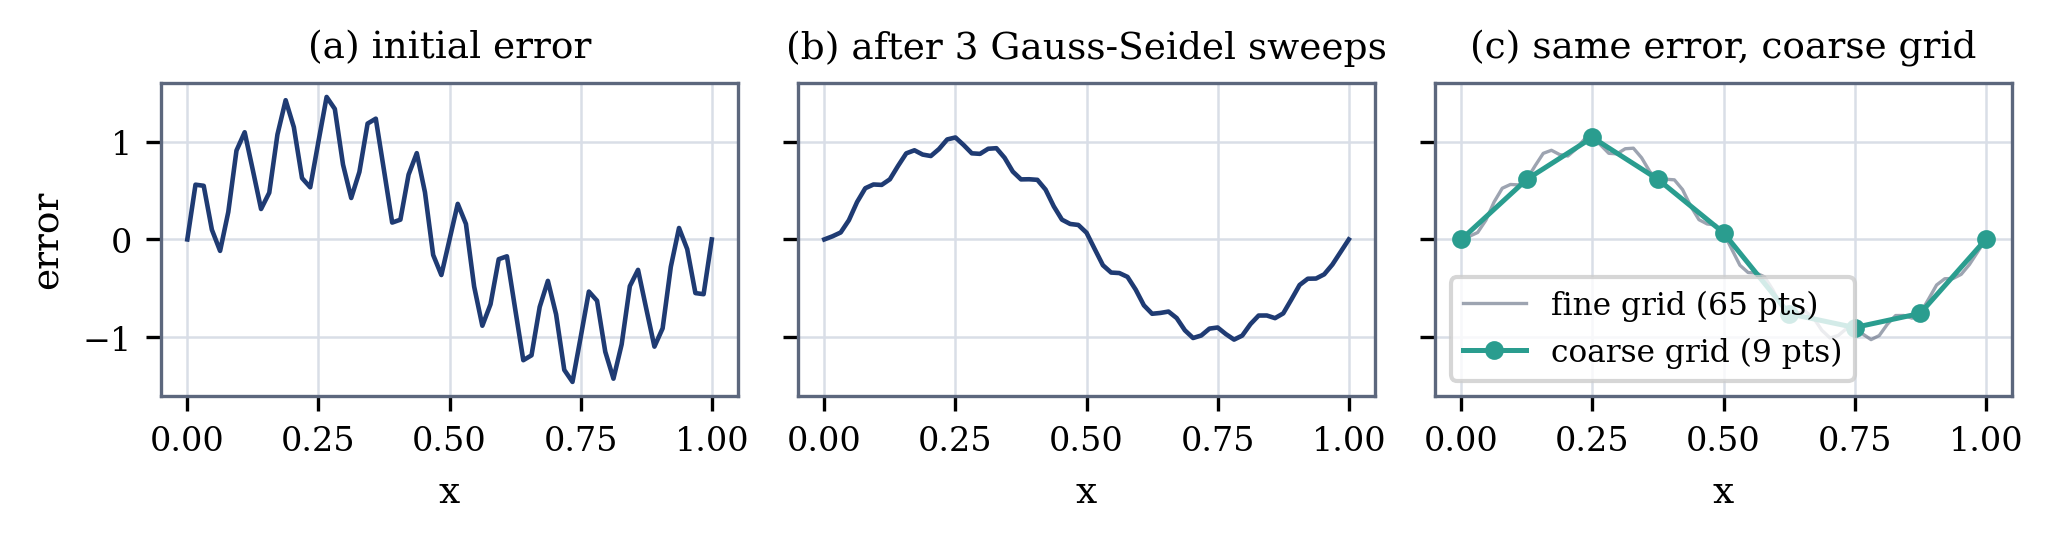

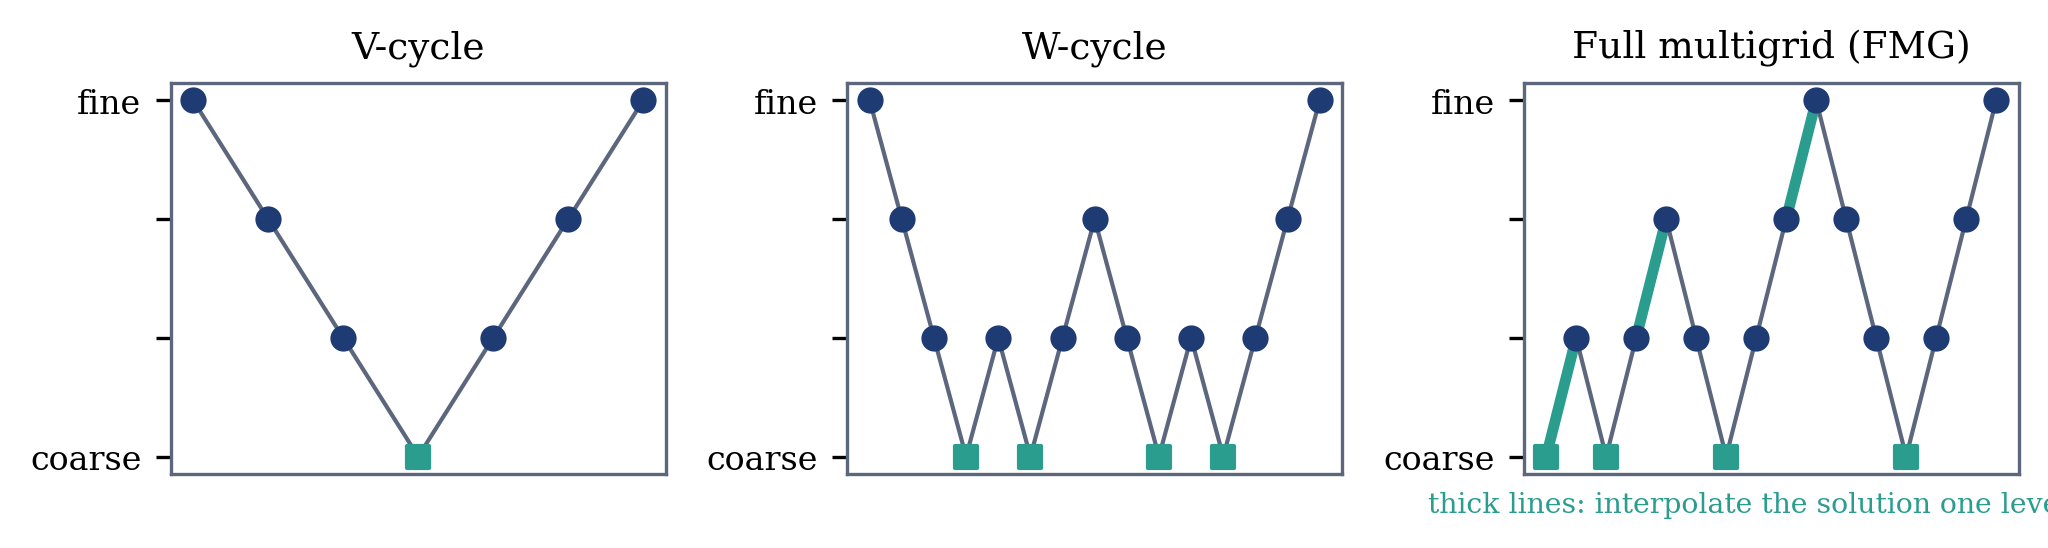

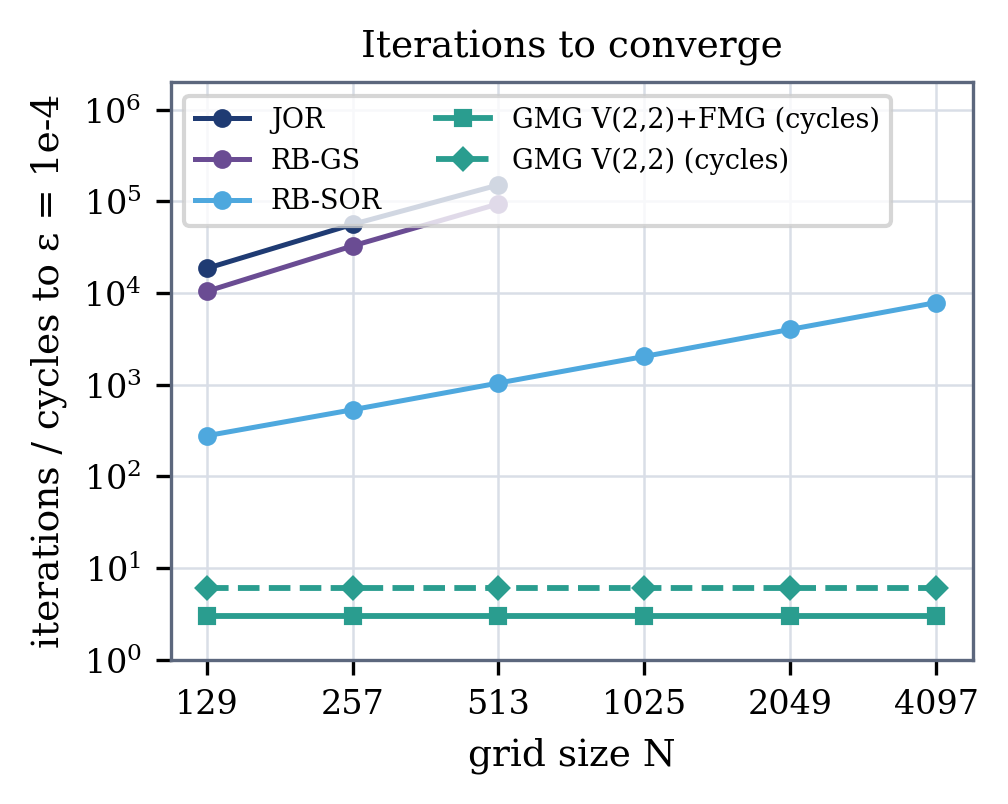

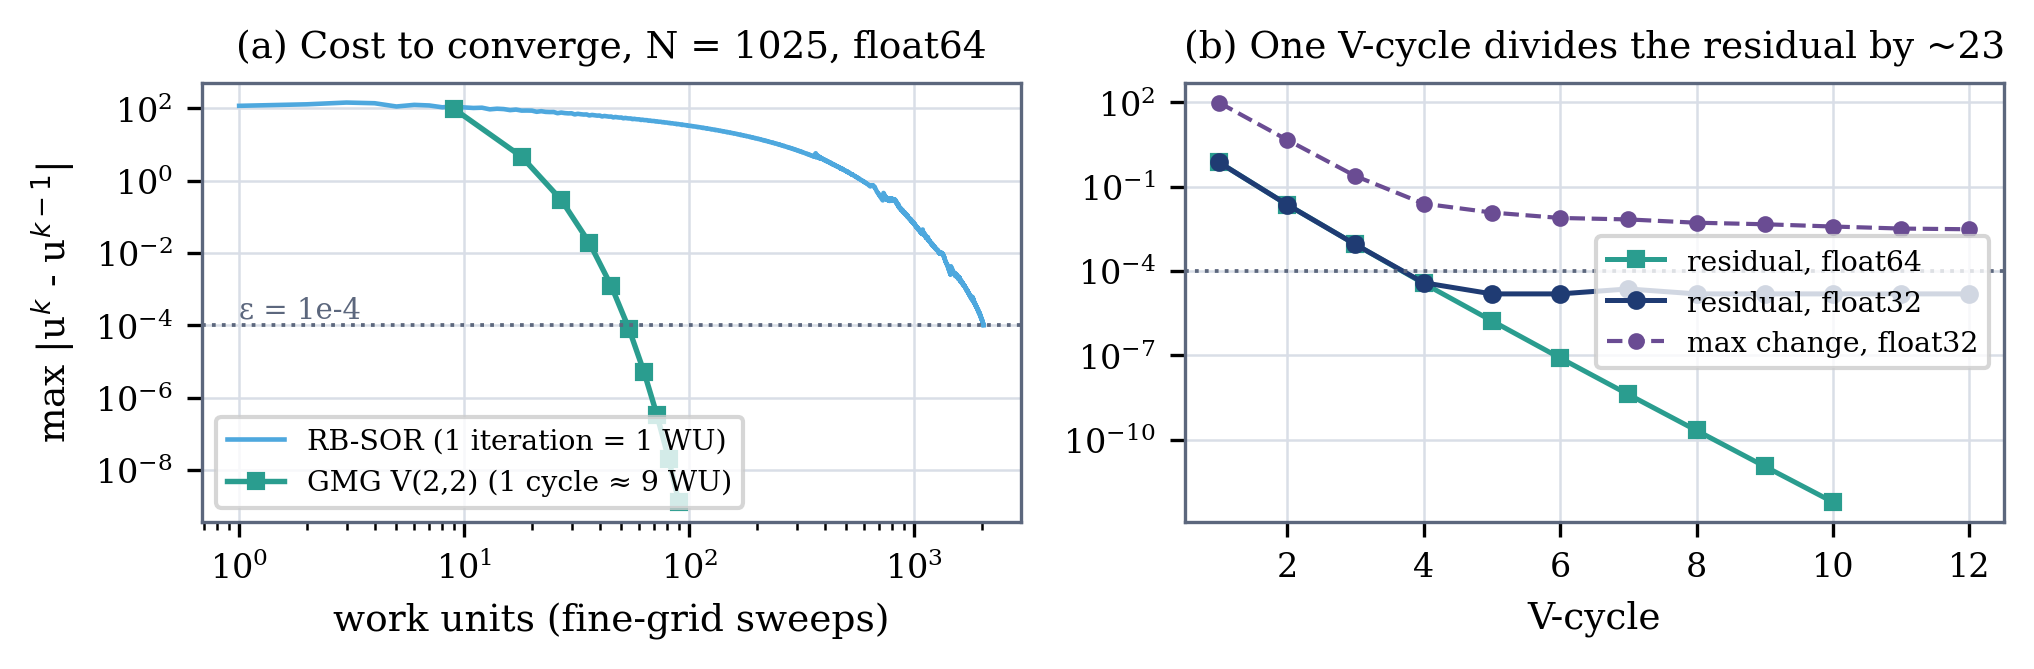

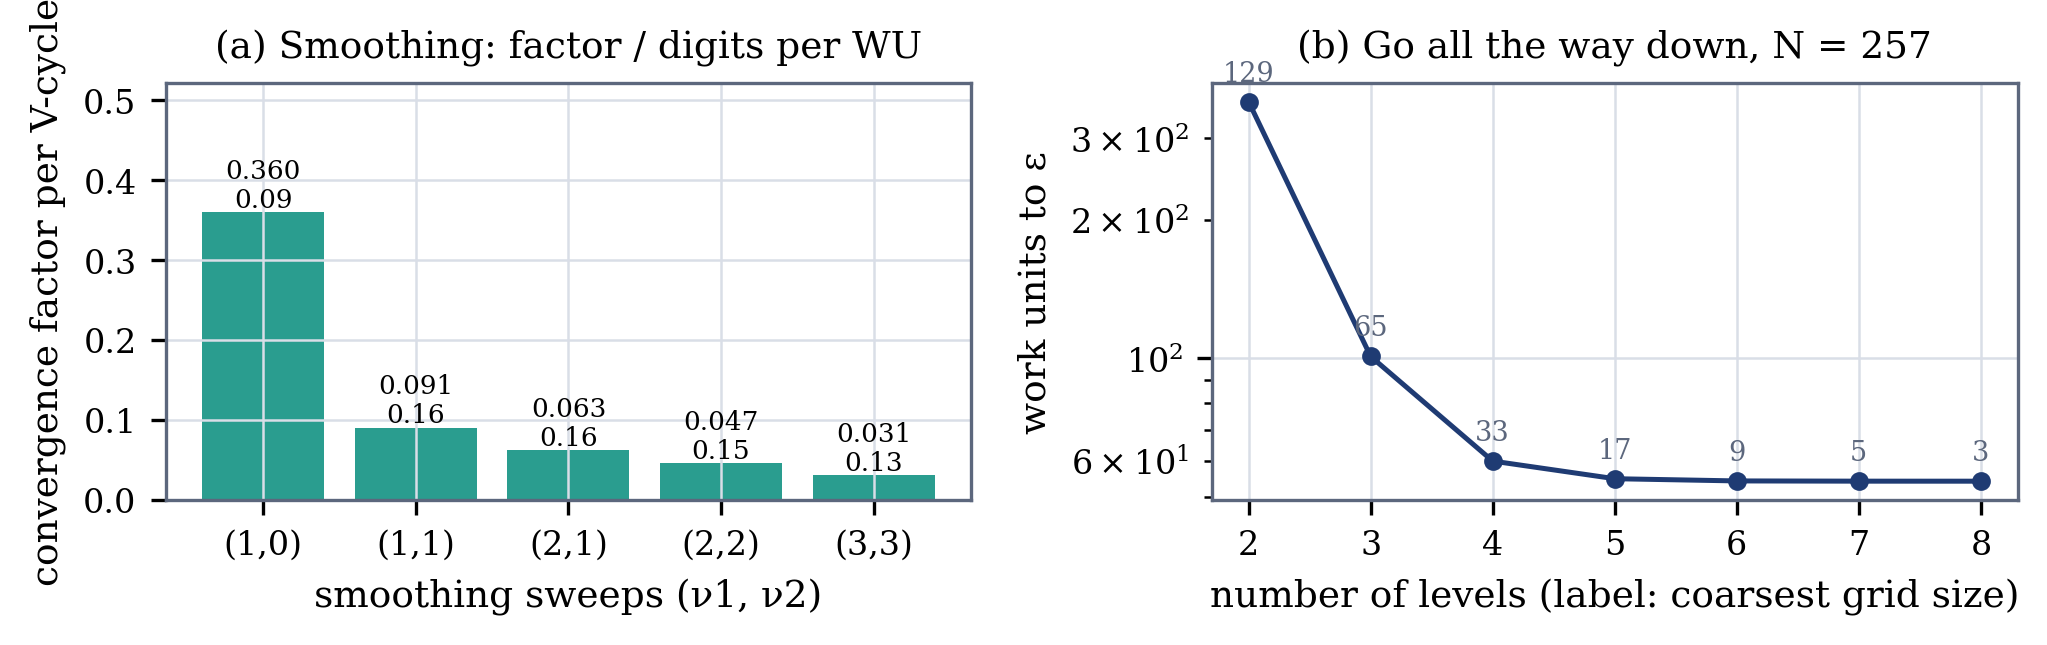

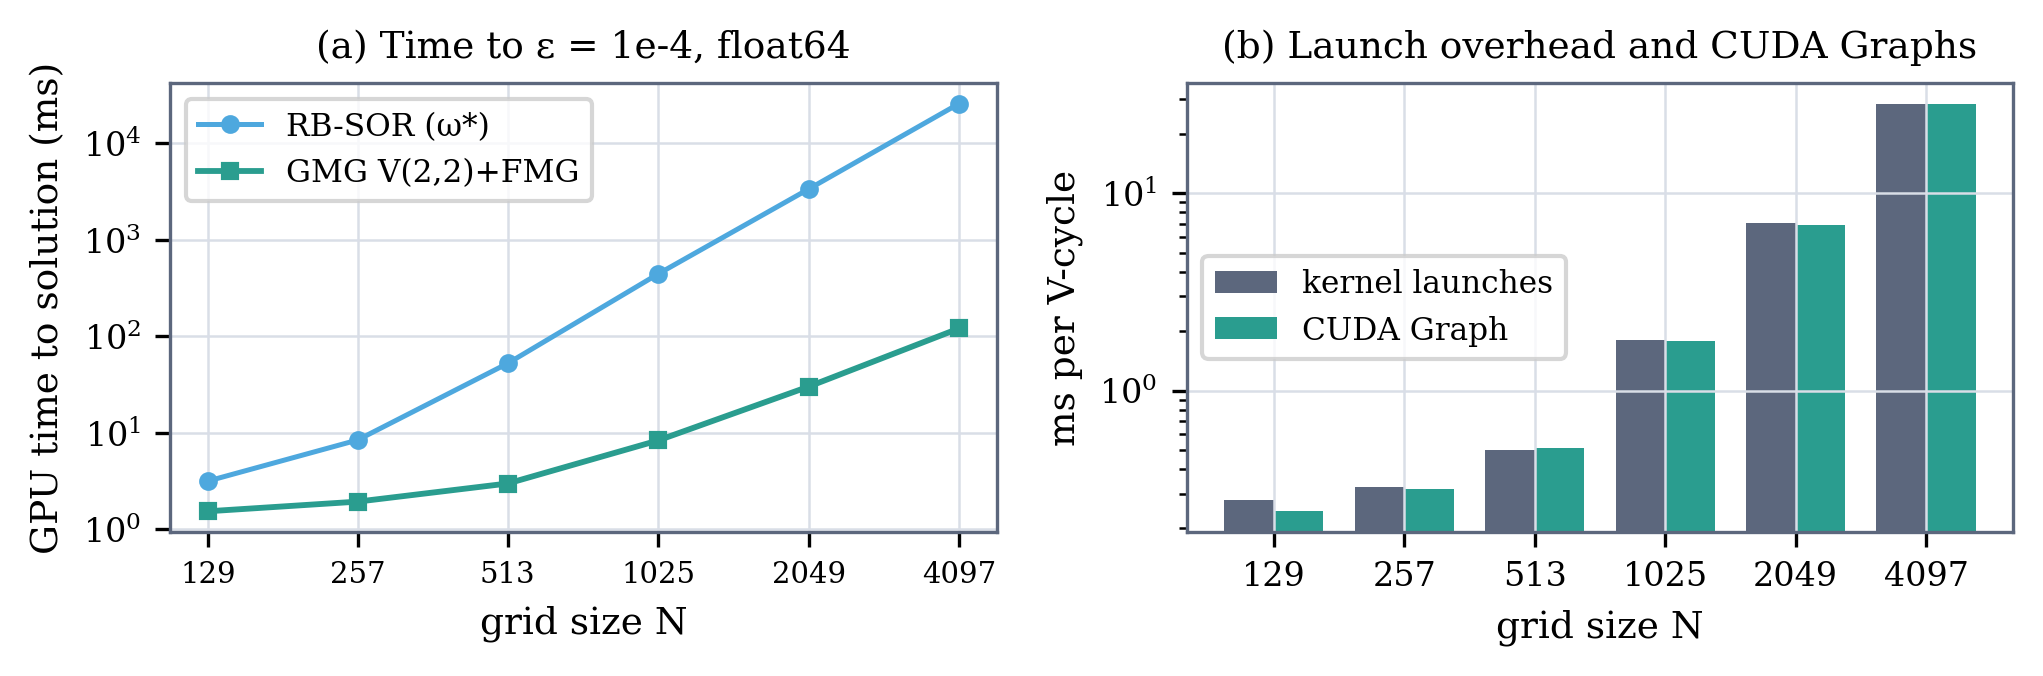

In [26]:
!python3 make_gmg_assets.py --data gdata --out assets
for f in ["fig_gmg_smoothing", "fig_gmg_cycles", "fig_gmg_iters", "fig_gmg_history", "fig_gmg_tuning", "fig_gmg_time"]:
    display(Image(f"assets/{f}.png", width=760 if f not in ("fig_gmg_iters",) else 470))

## 21. What to remember

| | JOR | RB-SOR | **GMG** |
|---|---|---|---|
| iterations to $\varepsilon$ | $O(N^2)$ | $O(N)$ | **O(1)**: about 3 cycles |
| work to solution | $O(N^4)$ | $O(N^3)$ | $O(N^2)$, optimal |
| needs a tuned parameter | no | yes ($\omega^*$) | no |
| error left at $\varepsilon = 10^{-4}$ | degrees | $10^{-3}$ | about $10^{-7}$ |
| float32 usable | yes, but inaccurate | no | only for small $N$ |

**Production checklist for this solver**
* Correctness: the GPU result matches a sequential reference (`--verify`), and boundary cells are never written.
* Robustness: input validation; NaN/overflow detection (exit code 3); a cycle budget (exit code 2); no silent failure.
* Performance: $O(N^2)$ total work, coalesced kernels, a CUDA Graph for the latency-bound coarse levels, no per-iteration host synchronisation.
* Accuracy: float64 by default. In float32 the residual can only be computed to about $\text{ulp}(T)\cdot N^2$, so the attainable change criterion grows with $N$.
* Limits: best with $N=2^k+1$; other sizes work but use a larger coarsest grid. Variable conductivity or irregular domains need operator-dependent or algebraic multigrid (e.g. NVIDIA AmgX, hypre).